# Does protection slow deforestation? Jaru Biological Reserve (Rondônia, Brazil), 2017-2025

This notebook compares forest loss between 2018 and 2025 **inside a strictly protected area** (IUCN category Ia) and **in a 10 km ring around it**. Forest is classified from Sentinel-1 and Sentinel-2 annual composites in Google Earth Engine (Python API). Uncertainty is quantified with an **independent validation sample labelled by an analyst**, following Olofsson et al. (2014).

**Data.** World Database on Protected Areas (WDPA) boundaries; Sentinel-2 L2A and Sentinel-1 GRD (Copernicus); Hansen Global Forest Change v1.13 (Hansen et al., 2013). Hansen is used to build training labels and as an independent product for comparison. It is **not** used as validation truth.

**Method in short.**
1. Dry-season composites per year (NDVI, NBR, VV, VH) and a random forest trained on high-confidence Hansen labels give an annual probability of forest.
2. A pixel is **lost** in year *Y* if it is forest in 2017 and stays non-forest from *Y* to 2025 (persistence rule). Loss patches smaller than 6 pixels (0.54 ha) are removed (minimum mapping unit). The probability threshold (0.3) and the minimum mapping unit were **fixed before the validation**.
3. A stratified random sample of 220 points is labelled blind (without the map), and area and accuracy are estimated with 95 % confidence intervals.
4. Inside and outside are compared by distance to the reserve boundary and at equal exposure to the deforestation front.

## Contents

| Step | Content | Runs on |
|---|---|---|
| 1 | Setup and Earth Engine access | Earth Engine |
| 2 | Study site selection | Earth Engine |
| 3 | Study area and 10 km ring | Earth Engine |
| 4 | Sentinel-1 and Sentinel-2 annual composites | Earth Engine |
| 5 | Training samples | Earth Engine, then local |
| 6 | Classification, export and loss mapping | Earth Engine (6.1-6.4), then local (6.5 onwards) |
| 7 | Validation and uncertainties | local, with one light Earth Engine request (7.3) |
| 8 | Inside versus outside | local |
| 9 | Final figures | local |
| 10 | README, one-page synthesis, CV line | outside this notebook |

## How to run

- Steps 1 to 6.4 need an Earth Engine account (noncommercial use) and a Google Cloud project. Set the environment variable `EE_PROJECT`, or edit `PROJECT` in step 1.1.
- Steps that consume Earth Engine quota (5.2, 6.3, 7.3) **only run when their switch is `True`** in step 1.1. By default, results already saved in `data/` are reused. The first time, set the switches to `True`; each yearly export used roughly 5,000 to 6,700 EECU-seconds (the noncommercial monthly quota is 540,000).
- Interactive Earth Engine maps (`geemap`) are deliberately not used. They recompute tiles at every pan or zoom and are a likely cause of heavy quota use.
- From step 6.5 onwards everything is local and only needs the files in `data/exports/`. After restarting the kernel, re-run 1.1, then 6.5, 6.6, 6.8 and 7.1 before any later step.
- Step 7.4 is interactive (labelling tool); steps 7.5 onwards only need `data/labels.csv`.

## About the outputs

The text outputs shown come from the original exploratory runs. The code in this version was tidied (numbered steps, caching, clearer names) without changing what is computed, apart from the additions flagged "new". Figures and the cells marked "new" show no output until you run them. Execution counters were renumbered in notebook order. To refresh everything that is local, run steps 6.5 to 9.

**References.** Hansen, M.C. et al. (2013) *Science* 342, 850-853. Olofsson, P. et al. (2014) *Remote Sensing of Environment* 148, 42-57.

## Step 1. Setup and Earth Engine access

### 1.1 Imports, parameters and switches
All parameters live here. The three switches control the steps that use Earth Engine quota.

In [1]:
# [1.1] Imports, parameters and switches
import os
import time

import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------------------
PROJECT = os.environ.get("EE_PROJECT", "noe-forest-protection")   # your Google Cloud project ID

SITE = "Reserva Biológica Do Jaru"        # WDPA name of the protected area
BUFFER_KM = 10                            # width of the comparison ring
YEARS = list(range(2017, 2026))           # annual composites 2017-2025
DRY_START, DRY_END = "05-01", "10-01"     # dry season: 1 May to 30 Sep (end date exclusive)
MAX_CLOUD = 60                            # tile-level cloud filter (%), same for every year

FEATURES = ["NDVI", "NBR", "VV", "VH"]    # variables used by the classifier
FEATURES_CANDIDATES = FEATURES + ["VH_VV"]   # VH_VV is screened and dropped in step 5.4

# Persistent-loss rule, fixed before the validation (see 6.6 and 6.8)
THR = 0.3     # a pixel is non-forest when P(forest) < THR
MMU = 6       # minimum mapping unit: 6 pixels of 30 m = 0.54 ha

# Paths
DATA_DIR = "data"
EXPORT_DIR = f"{DATA_DIR}/exports"
CHIP_DIR = f"{DATA_DIR}/chips"
FIG_DIR = "figures"
TRAIN_CSV = f"{DATA_DIR}/training_samples.csv"
for folder in (DATA_DIR, EXPORT_DIR, CHIP_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

# ---------------------------------------------------------------------------
# Switches. Steps that use Earth Engine quota are skipped when their results already
# exist on disk. Set a switch to True to run the step (the first time, or to refresh it).
# ---------------------------------------------------------------------------
RUN_TRAINING_SAMPLING = False   # 5.2: draw the 9,000 training points
RUN_EXPORTS = False             # 6.3: launch the 10 export tasks to Google Drive
RUN_CHIPS = False               # 7.3: fetch the reference image chips for the labelling

### 1.2 Earth Engine initialisation and test
`ee.Authenticate()` opens a browser window and is only needed once per computer. Do not publish the verification code it asks for.

In [1]:
# [1.2] Earth Engine initialisation and test
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()                    # opens a browser window; needed once per computer
    ee.Initialize(project=PROJECT)

# Sanity check: count Sentinel-2 scenes over an arbitrary point in 2024
point = ee.Geometry.Point([-52.9, 4.6])
n = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
       .filterBounds(point)
       .filterDate("2024-01-01", "2025-01-01")
       .size())
print("Sentinel-2 scenes in 2024:", n.getInfo())

Sentinel-2 scenes in 2024: 74


## Step 2. Study site selection

The aim is a strictly protected, large, forested area created well before 2017, with a surrounding ring that still contains forest once other protected areas are excluded. The tropical Brazilian "arc of deforestation" gives a strong contrast between protected and unprotected land.

### 2.1 WDPA attributes
The attribute names are checked rather than assumed (an earlier field name did not exist in this WDPA version).

In [2]:
# [2.1] WDPA attributes
# Rough bounding box of the Brazilian "arc of deforestation" (lon_min, lat_min, lon_max, lat_max)
arc = ee.Geometry.Rectangle([-66, -14, -48, -3])

# World Database on Protected Areas (polygons only)
wdpa = ee.FeatureCollection("WCMC/WDPA/current/polygons")

# Attribute names available for each protected area
print(wdpa.first().propertyNames().getInfo())

['REP_AREA', 'OWN_TYPE', 'REP_M_AREA', 'INT_CRIT', 'GOV_TYPE', 'SITE_PID', 'REALM', 'ISO3', 'GIS_AREA', 'DESIG', 'STATUS', 'NO_TAKE', 'INLND_WTRS', 'PRNT_ISO3', 'CONS_OBJ', 'GIS_M_AREA', 'SITE_TYPE', 'SITE_ID', 'NAME_ENG', 'DESIG_ENG', 'MANG_PLAN', 'SUPP_INFO', 'NAME', 'DESIG_TYPE', 'METADATAID', 'GOVSUBTYPE', 'MANG_AUTH', 'STATUS_YR', 'OWNSUBTYPE', 'OECM_ASMT', 'NO_TK_AREA', 'VERIF', 'IUCN_CAT', 'system:index']


### 2.2 Candidate protected areas
Filters: Brazil, terrestrial, legally in force, reported area of 1,000 to 6,000 km², creation year known and no later than 2012. Indigenous areas (no IUCN category) and categories V and VI (human use allowed) are then set aside by reading the table, which leaves the strict categories Ia and II.

In [3]:
# [2.2] Candidate protected areas
candidates = (
    wdpa
    .filterBounds(arc)
    .filter(ee.Filter.eq("ISO3", "BRA"))             # Brazil only
    .filter(ee.Filter.eq("REALM", "Terrestrial"))    # terrestrial only
    .filter(ee.Filter.eq("STATUS", "Designated"))    # legally in force
    .filter(ee.Filter.gte("REP_AREA", 1000))         # reported area, km2
    .filter(ee.Filter.lte("REP_AREA", 6000))
    .filter(ee.Filter.gt("STATUS_YR", 0))            # 0 means unknown year
    .filter(ee.Filter.lte("STATUS_YR", 2012))        # protected well before 2017
)

print("Candidates:", candidates.size().getInfo())

# Keep attributes only (no geometry) to stay light
fields = ["NAME", "DESIG_ENG", "IUCN_CAT", "REP_AREA", "STATUS_YR"]
feats = candidates.select(fields, None, False).limit(200).getInfo()["features"]

table = pd.DataFrame([f["properties"] for f in feats])
table = table.sort_values("REP_AREA", ascending=False).reset_index(drop=True)
print(table.to_string())

Candidates: 119
                                             DESIG_ENG      IUCN_CAT                                                                            NAME     REP_AREA  STATUS_YR
0                      Sustainable Development Reserve            VI                                  Reserva De Desenvolvimento Sustentável Do Juma  5807.874697       2006
1                                               Forest            VI                                                  Floresta Nacional Do Jatuarana  5682.889839       2002
2                        Environmental Protection Area             V                                   Área De Proteção Ambiental Do Lago De Tucurui  5682.325402       2002
3                                      Indigenous Area  Not Reported                                                                          Paresi  5635.865345       1987
4    Wetland of International Importance (Ramsar Site)  Not Reported                                                   

### 2.3 Screening the finalists with Hansen (coarse)
Five strict-category finalists are compared on forest area and Hansen loss 2017-2025, inside and in a 10 km ring outside every protected area. This screening uses a coarse 120 m scale and a loss denominator based on forest cover in 2000, so the numbers are **indicative only**: it ranks sites, it does not measure them. The final figures are computed at 30 m in steps 6 to 8.

In [4]:
# [2.3] Screening the finalists with Hansen (coarse)
finalists = ["Reserva Biológica Do Jaru",
             "Parque Estadual De Corumbiara",
             "Parque Nacional Serra Da Cutia",
             "Parque Estadual De Guajará-Mirim",
             "Parque Nacional Do Rio Novo"]

# All designated terrestrial protected areas in Brazil
all_pa = (wdpa.filter(ee.Filter.eq("ISO3", "BRA"))
              .filter(ee.Filter.eq("REALM", "Terrestrial"))
              .filter(ee.Filter.eq("STATUS", "Designated")))

hansen = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
forest_ee = hansen.select("treecover2000").gte(30)
lossyear_ee = hansen.select("lossyear")                       # 1 = 2001, ..., 25 = 2025
loss_ee = lossyear_ee.gte(17).And(lossyear_ee.lte(25)).And(forest_ee)   # loss 2017-2025

area_ee = ee.Image.pixelArea().divide(1e6)                    # km2 per pixel
# Raster mask: 1 on any protected area, 0 elsewhere (no heavy geometry work)
pa_all_ee = ee.Image(0).byte().paint(all_pa, 1)

def site_stats(name, scale=120):
    pa_fc = wdpa.filter(ee.Filter.eq("NAME", name))
    inside_img = ee.Image(0).byte().paint(pa_fc, 1)           # target area only
    ring_img = pa_all_ee.Not()                                # outside every protected area
    # Simplified buffer, used only as a cheap clipping region
    region = pa_fc.geometry().simplify(1000).buffer(10000, 1000)

    stack = ee.Image.cat([
        forest_ee.updateMask(inside_img).rename("forest_in"),
        loss_ee.updateMask(inside_img).rename("loss_in"),
        forest_ee.updateMask(ring_img).rename("forest_ring"),
        loss_ee.updateMask(ring_img).rename("loss_ring"),
    ]).multiply(area_ee)

    return stack.reduceRegion(ee.Reducer.sum(), region, scale,
                              maxPixels=1e11, tileScale=4).getInfo()

rows = []
for name in finalists:
    t0 = time.time()
    s = site_stats(name)
    rows.append({"area": name, **{k: round(v) for k, v in s.items()}})
    print(f"{name}: done in {time.time() - t0:.0f} s")

res = pd.DataFrame(rows)
res["loss_in_%"] = (100 * res.loss_in / res.forest_in).round(1)
res["loss_ring_%"] = (100 * res.loss_ring / res.forest_ring).round(1)
print(res.to_string())

Reserva Biológica Do Jaru: done in 3 s
Parque Estadual De Corumbiara: done in 2 s
Parque Nacional Serra Da Cutia: done in 2 s
Parque Estadual De Guajará-Mirim: done in 1 s
Parque Nacional Do Rio Novo: done in 2 s
                               area  forest_in  forest_ring  loss_in  loss_ring  loss_in_%  loss_ring_%
0         Reserva Biológica Do Jaru       3466         2590        5        261        0.1         10.1
1     Parque Estadual De Corumbiara       2160         2806      224        603       10.4         21.5
2    Parque Nacional Serra Da Cutia       2822          281      217         81        7.7         28.8
3  Parque Estadual De Guajará-Mirim       2212         1117      928        340       42.0         30.4
4       Parque Nacional Do Rio Novo       5380         1218      238         13        4.4          1.1


**Choice.** Jaru Biological Reserve combines strict protection (category Ia), a large forested interior and a ring with enough remaining forest. The other finalists were set aside: Serra da Cutia has too little forest in its ring, Rio Novo shows no inside/outside contrast, and Guajará-Mirim has an implausible inside loss that was not investigated. The choice was made on the contrast between protected and unprotected land, so the result applies to this site and must not be generalised to protection as a whole.

### 2.4 Chosen site
WDPA gives the creation year as 1961. Other sources cite a 1979 decree and an enlargement in 2006; in every case protection predates 2017.

In [5]:
# [2.4] Chosen site
site_fc = wdpa.filter(ee.Filter.eq("NAME", SITE))
print("Polygons named", SITE, ":", site_fc.size().getInfo())

fields = ["SITE_ID", "NAME", "DESIG_ENG", "IUCN_CAT", "STATUS",
          "STATUS_YR", "REP_AREA", "GIS_AREA"]
feats = site_fc.select(fields, None, False).getInfo()["features"]
print(pd.DataFrame([f["properties"] for f in feats]).to_string())

Polygons named Reserva Biológica Do Jaru : 1
            DESIG_ENG    GIS_AREA IUCN_CAT                       NAME     REP_AREA  SITE_ID      STATUS  STATUS_YR
0  Biological Reserve  3468.62657       Ia  Reserva Biológica Do Jaru  3468.647121       44  Designated       1961


## Step 3. Study area and 10 km ring

The **inside** is the reserve polygon. The **ring** is the zone within 10 km of the reserve, minus the reserve and minus every other designated protected area, so that the comparison opposes protected and unprotected land. Masks are rasterised (`paint`) instead of cutting geometries, which is much faster. Objects living in Earth Engine carry the suffix `_ee`; local numpy arrays (from step 6.5) have plain names.

### 3.1 Raster masks, ring and areas

In [6]:
# [3.1] Raster masks, ring and areas
# Study geometry: the buffer is only used as a calculation window
site_geom = site_fc.geometry()
buffer_geom = site_geom.simplify(100).buffer(BUFFER_KM * 1000, 100)

# Raster masks (1 = in the zone)
inside_ee = ee.Image(0).byte().paint(site_fc, 1).rename("inside")
in_buffer_ee = (ee.Image(0).byte()
                .paint(ee.FeatureCollection([ee.Feature(buffer_geom)]), 1))

# Raw ring: buffer minus the site only
ring_raw_ee = in_buffer_ee.And(inside_ee.Not()).rename("ring_raw")
# Final ring: buffer minus every protected area (site included)
ring_ee = in_buffer_ee.And(pa_all_ee.Not()).rename("ring")
study_ee = inside_ee.Or(ring_ee)                  # pixels used in the analysis

# Areas at the native Hansen resolution (30 m)
stack = ee.Image.cat([inside_ee, ring_raw_ee, ring_ee]).multiply(area_ee)
a = stack.reduceRegion(ee.Reducer.sum(), buffer_geom, 30,
                       maxPixels=1e10, tileScale=4).getInfo()
print({k: round(v) for k, v in a.items()})
print("Share of the raw ring removed (other protected areas): "
      f"{100 * (1 - a['ring'] / a['ring_raw']):.0f} %")

# Which protected areas are excluded from the ring?
others = (all_pa.filterBounds(buffer_geom)
                .filter(ee.Filter.neq("NAME", SITE)))
cols = ["NAME", "DESIG_ENG", "IUCN_CAT", "STATUS_YR"]
rows = others.select(cols, None, False).getInfo()["features"]
excl = pd.DataFrame([r["properties"] for r in rows])
print(len(excl), "other protected areas intersect the buffer")
print(excl.sort_values("NAME").to_string())

{'inside': 3469, 'ring': 2895, 'ring_raw': 3262}
Share of the raw ring removed (other protected areas): 11 %
3 other protected areas intersect the buffer
            DESIG_ENG      IUCN_CAT                               NAME  STATUS_YR
0     Indigenous Area  Not Reported                    Igarapé Lourdes       2002
2  Extractive Reserve            VI   Reserva Extrativista Aquariquara       1995
1  Extractive Reserve            VI  Reserva Extrativista Massaranduba       1995


**Limits of the ring.** Along the southern boundary the reserve touches an indigenous land that is excluded from the ring, so the ring is not a complete annulus. WDPA is not exhaustive: land with another special status may remain in the ring.

## Step 4. Sentinel-1 and Sentinel-2 annual composites

Each year is summarised over the **dry season** (1 May to 30 September), the least cloudy period in the region. The cost is that changes happening in the wet season are not seen.

### 4.1 Scene availability
Sentinel-1 is only available in descending orbit over the area, so orbits are never mixed.

In [7]:
# [4.1] Scene availability
s2 = ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))

def count_year(y):
    """Count Sentinel scenes over the study window for one dry season."""
    start, end = f"{y}-{DRY_START}", f"{y}-{DRY_END}"
    s2_y = s2.filterBounds(buffer_geom).filterDate(start, end)
    s1_y = s1.filterBounds(buffer_geom).filterDate(start, end)
    return ee.Dictionary({
        "year": y,
        "S2_all": s2_y.size(),
        "S2_cloud_lt_30": s2_y.filter(
            ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30)).size(),
        "S1_all": s1_y.size(),
        "S1_ascending": s1_y.filter(
            ee.Filter.eq("orbitProperties_pass", "ASCENDING")).size(),
        "S1_descending": s1_y.filter(
            ee.Filter.eq("orbitProperties_pass", "DESCENDING")).size(),
    })

counts = pd.DataFrame(ee.List([count_year(y) for y in YEARS]).getInfo())
print(counts.to_string(index=False))

 S1_all  S1_ascending  S1_descending  S2_all  S2_cloud_lt_30  year
     35             0             35      39              39  2017
     37             0             37      35              35  2018
     73             0             73     185             130  2019
     76             0             76     183             132  2020
     77             0             77     179             121  2021
     37             0             37     184             133  2022
     30             0             30     184             127  2023
     30             0             30     189             140  2024
     52             0             52     263             188  2025


### 4.2 Tiles and acquisition days
2017 and 2018 have about four times fewer scenes than later years. All four tiles are present every year, so the difference is temporal (fewer acquisition days), not spatial holes. The cause was not established.

In [8]:
# [4.2] Tiles and acquisition days
def n_distinct_days(col):
    """Number of distinct acquisition days in a collection."""
    days = (col.aggregate_array("system:time_start")
               .map(lambda t: ee.Date(t).format("YYYY-MM-dd")))
    return ee.List(days).distinct().size()

def diag_year(y):
    start, end = f"{y}-{DRY_START}", f"{y}-{DRY_END}"
    s2_y = s2.filterBounds(buffer_geom).filterDate(start, end)
    s1_y = s1.filterBounds(buffer_geom).filterDate(start, end)
    return ee.Dictionary({
        "year": y,
        "S2_tiles": ee.List(s2_y.aggregate_array("MGRS_TILE")).distinct().size(),
        "S2_days": n_distinct_days(s2_y),
        "S2_scenes": s2_y.size(),
        "S1_days": n_distinct_days(s1_y),
        "S1_scenes": s1_y.size(),
        "S2_tile_names": ee.List(s2_y.aggregate_array("MGRS_TILE")).distinct(),
    })

diag = pd.DataFrame(ee.List([diag_year(y) for y in YEARS]).getInfo())
print(diag.to_string(index=False))

 S1_days  S1_scenes  S2_days  S2_scenes                S2_tile_names  S2_tiles  year
      24         35       16         39 [20LNP, 20LNQ, 20LPP, 20LPQ]         4  2017
      24         37       15         35 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2018
      49         73       60        185 [20LNP, 20LNQ, 20LPP, 20LPQ]         4  2019
      50         76       61        183 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2020
      51         77       60        179 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2021
      25         37       60        184 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2022
      21         30       60        184 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2023
      20         30       61        189 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2024
      36         52       72        263 [20LPP, 20LPQ, 20LNP, 20LNQ]         4  2025


### 4.3 Composite definitions
- **Sentinel-2**: median over the dry season of NDVI and NBR, after masking clouds, shadows, cirrus and saturated pixels with the scene classification band (SCL classes 4 to 7 are kept), plus a count of valid observations.
- **Sentinel-1**: median backscatter in dB (VV, VH, VH minus VV), descending orbit only.

Nothing is computed here: these are recipes, evaluated only when a result is requested.

In [9]:
# [4.3] Composite definitions
def s2_composite(year):
    """Dry-season median of NDVI and NBR, plus a count of valid observations."""
    start, end = f"{year}-{DRY_START}", f"{year}-{DRY_END}"

    def prep(img):
        scl = img.select("SCL")
        # Keep vegetation (4), bare soil (5), water (6), unclassified (7)
        valid = scl.gte(4).And(scl.lte(7))
        ndvi = img.normalizedDifference(["B8", "B4"]).rename("NDVI")
        nbr = img.normalizedDifference(["B8", "B12"]).rename("NBR")
        return ee.Image.cat([ndvi, nbr]).updateMask(valid)

    col = (s2.filterBounds(buffer_geom)
             .filterDate(start, end)
             .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD))
             .map(prep))
    n_valid = col.select("NDVI").count().rename("n_valid_s2")
    return col.median().addBands(n_valid)

def s1_composite(year):
    """Dry-season median backscatter (dB), descending orbit only."""
    start, end = f"{year}-{DRY_START}", f"{year}-{DRY_END}"
    col = (s1.filterBounds(buffer_geom)
             .filterDate(start, end)
             .filter(ee.Filter.eq("orbitProperties_pass", "DESCENDING"))
             .select(["VV", "VH"]))
    med = col.median()
    return (med
            .addBands(med.select("VH").subtract(med.select("VV")).rename("VH_VV"))
            .addBands(col.select("VV").count().rename("n_s1")))

# Nothing is computed yet: these are only recipes
composites = {y: s2_composite(y).addBands(s1_composite(y)) for y in YEARS}
print("Bands:", composites[2019].bandNames().getInfo())

Bands: ['NDVI', 'NBR', 'n_valid_s2', 'VV', 'VH', 'VH_VV', 'n_s1']


### 4.4 Valid observations per year
Share of study pixels with at least 1 and at least 3 valid Sentinel-2 observations, and mean number of observations per pixel. Coverage is sufficient every year, but 2017 and 2018 rest on about four times fewer observations per pixel than later years.

In [10]:
# [4.4] Valid observations per year
def qa_year(y):
    c = composites[y]
    n = c.select("n_valid_s2")
    qa = ee.Image.cat([
        n.rename("mean_n_s2"),
        n.gte(1).rename("share_ge1"),
        n.gte(3).rename("share_ge3"),
        c.select("n_s1").rename("mean_n_s1"),
    ]).updateMask(study_ee)
    return qa.reduceRegion(ee.Reducer.mean(), buffer_geom, 60,
                           maxPixels=1e10, tileScale=4).getInfo()

rows = []
for y in YEARS:
    t0 = time.time()
    rows.append({"year": y, **qa_year(y)})
    print(f"{y}: done in {time.time() - t0:.0f} s")

qa_table = pd.DataFrame(rows).round(2)
print(qa_table.to_string(index=False))

2017: done in 4 s
2018: done in 4 s
2019: done in 14 s
2020: done in 10 s
2021: done in 10 s
2022: done in 17 s
2023: done in 13 s
2024: done in 13 s
2025: done in 25 s
 year  mean_n_s1  mean_n_s2  share_ge1  share_ge3
 2017      12.14      10.59          1        1.0
 2018      13.96       8.04          1        1.0
 2019      26.26      35.21          1        1.0
 2020      28.09      36.43          1        1.0
 2021      28.18      33.64          1        1.0
 2022      13.13      35.05          1        1.0
 2023      10.04      32.02          1        1.0
 2024      10.88      37.82          1        1.0
 2025      18.36      50.73          1        1.0


### 4.5 Stable-forest mask
"Stable forest" is forest in 2000 (tree cover of at least 30 %) with no Hansen loss up to 2025, inside the reserve. It is used to check that composites are consistent from year to year, and later to measure false loss.

**Pitfall.** Hansen's `lossyear` band is masked where no loss occurred, so `lossyear.eq(0)` returns nothing and the stable area is empty. The comparison below shows the first variant giving 0 km² and the version with `unmask(0)` giving the expected area.

In [11]:
# [4.5] Stable-forest mask
variants = {
    # First version (mask left as is): empty result
    "as_before": forest_ee.And(lossyear_ee.eq(0)).And(inside_ee),
    # Version where masked pixels are set to 0 first
    "unmasked": forest_ee.unmask(0).And(lossyear_ee.unmask(0).eq(0)).And(inside_ee),
}

areas = ee.Image.cat([v.rename(k) for k, v in variants.items()]).multiply(area_ee)
a = areas.reduceRegion(ee.Reducer.sum(), site_geom, 60,
                       maxPixels=1e10, tileScale=4).getInfo()
print("Stable forest area inside the reserve (km2):", a)

stable_ee = variants["unmasked"]

Stable forest area inside the reserve (km2): {'as_before': 0, 'unmasked': 3371.2846909337586}


### 4.6 Composite consistency on stable forest
A forest that did not change should look the same every year. The radar means vary by about 0.5 dB and NBR shows no step. NDVI is about 0.03 lower from 2019 than in 2017-2018, small compared with the gap between forest and non-forest. No year-by-year correction was applied.

In [12]:
# [4.6] Composite consistency on stable forest
reducer = ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True)

def stable_stats(y):
    c = composites[y].select(["NDVI", "NBR", "VV", "VH"]).updateMask(stable_ee)
    return c.reduceRegion(reducer, site_geom, 60,
                          maxPixels=1e10, tileScale=4).getInfo()

rows = []
for y in YEARS:
    rows.append({"year": y, **stable_stats(y)})
    print(y, "done")

stab = pd.DataFrame(rows).round(3)
print(stab.to_string(index=False))

2017 done
2018 done
2019 done
2020 done
2021 done
2022 done
2023 done
2024 done
2025 done
 year  NBR_mean  NBR_stdDev  NDVI_mean  NDVI_stdDev  VH_mean  VH_stdDev  VV_mean  VV_stdDev
 2017     0.669       0.031      0.870        0.031  -14.139      0.970   -8.194      1.013
 2018     0.660       0.030      0.872        0.029  -14.196      0.970   -8.275      1.001
 2019     0.656       0.031      0.842        0.031  -14.472      0.927   -8.173      0.970
 2020     0.654       0.032      0.841        0.031  -14.481      0.926   -8.146      0.970
 2021     0.657       0.032      0.838        0.031  -14.595      0.924   -8.255      0.966
 2022     0.665       0.030      0.839        0.029  -14.580      0.960   -8.350      0.991
 2023     0.654       0.029      0.844        0.028  -14.372      1.004   -8.089      1.039
 2024     0.648       0.032      0.828        0.032  -14.524      0.967   -8.394      0.990
 2025     0.662       0.029      0.860        0.028  -14.521      0.954   -8.358  

## Step 5. Training samples

### 5.1 Training labels from Hansen
For year *Y* (with *k* = *Y* - 2000, Hansen coding 2001 as 1):
- **forest**: tree cover in 2000 of at least 30 % and no loss before or during *Y*;
- **non-forest**: tree cover in 2000 below 10 %, or loss at least one year before *Y*;
- **excluded**: loss during *Y* itself, tree cover between 10 and 30 %, and a 30 m erosion along edges.

This is label noise by construction: Hansen has its own errors, and secondary regrowth after an old loss can look like forest while still labelled non-forest.

In [ ]:
# [5.1] Training labels from Hansen
N_PER_CLASS = 500                                  # training points per class and year

# Unmask: Hansen masks pixels without loss, which we must treat as 0
tc2000_ee = hansen.select("treecover2000").unmask(0)
ly_ee = hansen.select("lossyear").unmask(0)

def label_image(year):
    """1 = forest, 0 = non-forest, masked = ambiguous or unlabelled."""
    k = year - 2000                                # Hansen codes 2001 as 1
    forest = tc2000_ee.gte(30).And(ly_ee.eq(0).Or(ly_ee.gt(k)))
    nonforest = tc2000_ee.lt(10).Or(ly_ee.gt(0).And(ly_ee.lt(k)))
    # Erode by one 30 m pixel to avoid mixed pixels along edges
    forest = forest.focalMin(1, "square", "pixels")
    nonforest = nonforest.focalMin(1, "square", "pixels")
    label = ee.Image(0).where(forest, 1).updateMask(forest.Or(nonforest))
    return label.rename("label").toByte()

### 5.2 Stratified sampling
500 forest and 500 non-forest points per year, drawn at 30 m inside the study area (9,000 points). The result is saved to `data/training_samples.csv` and reused afterwards. **Uses Earth Engine quota** (switch `RUN_TRAINING_SAMPLING`). The output shown is from the first run.

In [13]:
# [5.2] Stratified sampling (cached)
def sample_year(year):
    """Stratified random points with features and label for one year."""
    img = composites[year].select(FEATURES_CANDIDATES).addBands(inside_ee)   # keep 'inside' flag
    lab = label_image(year).updateMask(study_ee)
    fc = img.addBands(lab).stratifiedSample(
        numPoints=N_PER_CLASS, classBand="label", region=buffer_geom,
        scale=30, seed=year, classValues=[0, 1],
        classPoints=[N_PER_CLASS, N_PER_CLASS],
        tileScale=4, geometries=True)
    rows = []
    for f in fc.getInfo()["features"]:
        lon, lat = f["geometry"]["coordinates"]
        rows.append({"year": year, "lon": lon, "lat": lat, **f["properties"]})
    return pd.DataFrame(rows)

if RUN_TRAINING_SAMPLING:
    samples = {}
    for y in YEARS:
        t0 = time.time()
        samples[y] = sample_year(y)
        print(f"{y}: {len(samples[y])} points in {time.time() - t0:.0f} s")
    pd.concat(samples.values(), ignore_index=True).to_csv(TRAIN_CSV, index=False)
elif os.path.exists(TRAIN_CSV):
    print("RUN_TRAINING_SAMPLING = False: reusing", TRAIN_CSV)
else:
    raise FileNotFoundError(f"{TRAIN_CSV} not found: set RUN_TRAINING_SAMPLING = True "
                            "in step 1.1 and run this step once.")

2017: 1000 points in 13 s
2018: 1000 points in 14 s
2019: 1000 points in 44 s
2020: 1000 points in 37 s
2021: 1000 points in 28 s
2022: 1000 points in 46 s
2023: 1000 points in 45 s
2024: 1000 points in 43 s
2025: 1000 points in 47 s


### 5.3 Sample checks
Classes are balanced by construction. A handful of non-forest points fall inside the reserve (natural openings, old clearings). The forest NDVI is about 0.03 lower from 2019, in line with step 4.6, and far smaller than the gap between classes.

In [14]:
# [5.3] Sample checks
train = pd.read_csv(TRAIN_CSV)

print("Points per year and class:")
print(train.groupby(["year", "label"]).size().unstack())

print("\nPoints per class, inside the reserve (1) or in the ring (0):")
print(pd.crosstab(train["label"], train["inside"]))

print("\nMean features by class (all years):")
print(train.groupby("label")[FEATURES_CANDIDATES].mean().round(3))

print("\nMean NDVI by year and class:")
print(train.groupby(["year", "label"])["NDVI"].mean().unstack().round(3))

print("\nTraining samples file:", TRAIN_CSV)

Points per year and class:
label    0    1
year           
2017   500  500
2018   500  500
2019   500  500
2020   500  500
2021   500  500
2022   500  500
2023   500  500
2024   500  500
2025   500  500

Points per class, inside the reserve (1) or in the ring (0):
inside     0     1
label             
0       4276   224
1       1659  2841

Mean features by class (all years):
        NDVI    NBR      VV      VH  VH_VV
label                                     
0      0.470  0.227 -10.949 -17.017 -6.068
1      0.847  0.655  -8.375 -14.552 -6.177

Mean NDVI by year and class:
label      0      1
year               
2017   0.473  0.867
2018   0.515  0.876
2019   0.492  0.841
2020   0.463  0.838
2021   0.433  0.837
2022   0.465  0.834
2023   0.482  0.842
2024   0.403  0.828
2025   0.508  0.857

Training samples file: data/training_samples.csv


### 5.4 Feature screening (new)
Which variables help separate forest from non-forest? The agreement below is measured against **Hansen labels on high-confidence pixels** with one year held out. It is an internal check, **not map accuracy**: ambiguous and edge pixels are excluded by construction, labels come from an optical product, and neighbouring points are correlated.

`VH_VV` has almost no discriminating power and is dropped. Radar adds little to optical in the dry season here; the labels being optical-derived favours optical, and radar would matter more in the wet season.

In [15]:
# [5.4] Feature screening (new)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

print("Separability of forest vs non-forest per variable (AUC; 0.5 = none, 1 = perfect):")
for f in FEATURES_CANDIDATES:
    auc = roc_auc_score(train.label, train[f])
    print(f"  {f:6s} {max(auc, 1 - auc):.3f}")

def leave_one_year_out(features):
    """Agreement with the Hansen labels on a held-out year (internal check, not map accuracy)."""
    out = {}
    for y in sorted(train.year.unique()):
        tr, te = train[train.year != y], train[train.year == y]
        model = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
        model.fit(tr[features], tr.label)
        out[y] = round(float((model.predict(te[features]) == te.label).mean()), 3)
    return out

print("\nLeave-one-year-out agreement with the Hansen labels:")
for name, feats in {"five variables": FEATURES_CANDIDATES, "final four": FEATURES,
                    "optical only": ["NDVI", "NBR"], "radar only": ["VV", "VH"]}.items():
    acc = leave_one_year_out(feats)
    print(f"  {name:15s} min {min(acc.values()):.3f}  max {max(acc.values()):.3f}  "
          f"by year {list(acc.values())}")

Separability of forest vs non-forest per variable (AUC; 0.5 = none, 1 = perfect):
  NDVI   0.949
  NBR    0.960
  VV     0.850
  VH     0.833
  VH_VV  0.545

Leave-one-year-out agreement with the Hansen labels:
  five variables  min 0.912  max 0.955  by year [0.941, 0.912, 0.953, 0.947, 0.955, 0.931, 0.955, 0.944, 0.955]
  final four      min 0.912  max 0.956  by year [0.94, 0.912, 0.95, 0.949, 0.954, 0.933, 0.955, 0.946, 0.956]
  optical only    min 0.904  max 0.955  by year [0.935, 0.904, 0.947, 0.948, 0.952, 0.937, 0.954, 0.943, 0.955]
  radar only      min 0.741  max 0.805  by year [0.744, 0.752, 0.741, 0.77, 0.767, 0.768, 0.745, 0.805, 0.756]


## Step 6. Classification, export and loss mapping

### 6.1 Random forest
200 trees, probability output, four variables, trained on the 9,000 pooled points of all years so that one classifier learns the year-to-year variability. The out-of-bag error is an internal, optimistic estimate of agreement with the Hansen labels, **not** the accuracy of the map. Variable importances are nearly equal because NDVI and NBR (and VV and VH) are redundant pairs.

In [16]:
# [6.1] Random forest
train_df = pd.read_csv(TRAIN_CSV)

# Send the 9,000 samples to Earth Engine as a FeatureCollection (no geometry needed)
train_fc = ee.FeatureCollection([
    ee.Feature(None, {**{f: float(r[f]) for f in FEATURES}, "label": int(r["label"])})
    for r in train_df.to_dict("records")
])

rf = (ee.Classifier.smileRandomForest(numberOfTrees=200, seed=42)
        .setOutputMode("PROBABILITY")      # output = probability of forest (label 1)
        .train(features=train_fc, classProperty="label", inputProperties=FEATURES))

info = rf.explain().getInfo()
print("Variable importance:", info.get("importance"))
print("Out-of-bag error:", info.get("outOfBagErrorEstimate"))

Variable importance: {'NBR': 2534.4009005494872, 'NDVI': 2525.7228811758, 'VH': 2393.079807106126, 'VV': 2416.931992051256}
Out-of-bag error: 0.05644444444444444


### 6.2 Annual probability maps
One probability-of-forest image per year (recipes, nothing is computed until the export).

In [ ]:
# [6.2] Annual probability maps
def p_forest(year):
    """Probability of forest for one year, from the annual composite."""
    return composites[year].select(FEATURES).classify(rf).rename("p_forest")

prob_ee = {y: p_forest(y) for y in YEARS}      # recipes only, nothing is computed yet

### 6.3 Export to Google Drive
Everything after this step is done locally, so the annual probabilities are exported **once**: P(forest) x 100 stored as a byte (0-100, 255 = no data), one GeoTIFF per year, plus one file of static layers (Hansen, reserve, ring, protected areas), all on the same 30 m grid in UTM zone 20S (EPSG:32720). **Uses Earth Engine quota** (switch `RUN_EXPORTS`); tasks run in the background, one at a time.

When the 10 tasks are `COMPLETED`, download the files from the Drive folder `forest_protection_exports` into `data/exports/`.

In [17]:
# [6.3] Export to Google Drive
EXPORT_FOLDER = "forest_protection_exports"        # Google Drive folder
EXPORT_CRS = "EPSG:32720"                          # UTM zone 20S: metric grid, 30 m pixels
export_names = [f"p_forest_{y}" for y in YEARS] + ["static_layers"]

def start_export(image, name):
    task = ee.batch.Export.image.toDrive(
        image=image, description=name, folder=EXPORT_FOLDER,
        fileNamePrefix=name, region=buffer_geom.bounds(),     # same rectangle for every task
        scale=30, crs=EXPORT_CRS, maxPixels=1e10, fileFormat="GeoTIFF")
    task.start()
    return task

tasks = {}
if RUN_EXPORTS:
    # One file per year: P(forest) x 100 stored as a byte (0-100), 255 = no data
    for y in YEARS:
        img = (prob_ee[y].multiply(100).round().toByte()
                 .updateMask(in_buffer_ee).unmask(255)
                 .rename(f"p_forest_{y}"))
        tasks[f"p_forest_{y}"] = start_export(img, f"p_forest_{y}")

    # One file for the static layers (Hansen, reserve, ring, protected areas)
    static_img = ee.Image.cat([
        hansen.select("treecover2000").unmask(0).toByte().rename("treecover2000"),
        hansen.select("lossyear").unmask(0).toByte().rename("lossyear"),
        inside_ee.toByte().rename("inside"),
        ring_ee.toByte().rename("ring"),
        pa_all_ee.toByte().rename("protected_area_any"),
    ])
    tasks["static_layers"] = start_export(static_img, "static_layers")
    print(len(tasks), "export tasks started")
else:
    missing = [n for n in export_names if not os.path.exists(f"{EXPORT_DIR}/{n}.tif")]
    if missing:
        print("Missing in", EXPORT_DIR, ":", missing,
              "-> set RUN_EXPORTS = True, then download the files from Drive.")
    else:
        print("RUN_EXPORTS = False: reusing the 10 rasters already in", EXPORT_DIR)

10 export tasks started


### 6.4 Export status
States are `READY` (queued), `RUNNING`, `COMPLETED` or `FAILED` (with a message). Tasks keep running if the notebook is closed.

In [18]:
# [6.4] Export status
if not tasks:
    print("No task started in this session (see the Tasks tab of the Earth Engine console).")
for name, t in tasks.items():
    s = t.status()
    print(f"{name:18s} {s['state']:10s} {s.get('error_message', '')}")

p_forest_2017      COMPLETED  
p_forest_2018      COMPLETED  
p_forest_2019      COMPLETED  
p_forest_2020      COMPLETED  
p_forest_2021      COMPLETED  
p_forest_2022      COMPLETED  
p_forest_2023      COMPLETED  
p_forest_2024      COMPLETED  
p_forest_2025      COMPLETED  
static_layers      COMPLETED  


### 6.5 Load the exported rasters (local from here)
From this point no Earth Engine call is needed. The exports are read into numpy arrays on a common 30 m grid. Hansen is rebuilt at 30 m: `forest17_h` is forest at the start of 2018 (tree cover in 2000 of at least 30 % and no loss up to 2017), `loss_h` is Hansen loss in 2018-2025, and `stable` is stable forest inside the reserve.

In [2]:
# [6.5] Load the exported rasters
import rasterio
from scipy import ndimage

def read_exports():
    """Read the exported rasters (30 m, EPSG:32720) into numpy arrays."""
    p = {}                                          # P(forest) x 100 per year, uint8, 255 = no data
    for y in YEARS:
        with rasterio.open(f"{EXPORT_DIR}/p_forest_{y}.tif") as src:
            p[y] = src.read(1)
            profile = src.profile
    with rasterio.open(f"{EXPORT_DIR}/static_layers.tif") as src:
        static = src.read()
        descriptions = src.descriptions
    return p, profile, static, descriptions

p, profile, static, descriptions = read_exports()
assert descriptions == ("treecover2000", "lossyear", "inside", "ring", "protected_area_any"), descriptions
treecover2000, lossyear, inside, ring, any_pa = static          # bands in the export order
inside, ring = inside == 1, ring == 1
PIX_M = abs(profile["transform"][0])                # pixel size in metres
PIX_KM2 = PIX_M ** 2 / 1e6                          # pixel area in km2 (0.0009 for 30 m)

# Hansen reference at 30 m
forest17_h = (treecover2000 >= 30) & ((lossyear == 0) | (lossyear >= 18))   # forest at the start of 2018
loss_h = forest17_h & (lossyear >= 18) & (lossyear <= 25)                   # Hansen loss 2018-2025
stable = (treecover2000 >= 30) & (lossyear == 0) & inside                   # stable forest in the reserve

print("Band descriptions:", descriptions)
print("CRS:", profile["crs"], "| shape:", p[2017].shape, "| pixel size:", PIX_M, "m")
print("Same shape for all years:", all(p[y].shape == p[2017].shape for y in YEARS))
print("Inside:", round(inside.sum() * PIX_KM2), "km2 | ring:", round(ring.sum() * PIX_KM2), "km2")

Band descriptions: ('treecover2000', 'lossyear', 'inside', 'ring', 'protected_area_any')
CRS: EPSG:32720 | shape: (4332, 2574) | pixel size: 30.0 m
Same shape for all years: True
Inside: 3468 km2 | ring: 2895 km2


### 6.6 Persistent-loss rule
A pixel is **lost in year *Y*** if it is forest in 2017 (P(forest) of at least 0.5) and non-forest (P(forest) below the threshold) in year *Y* and in every later year. This removes isolated single-year flags but also transient events. Note the end effect: in 2025 a single non-forest year already counts, because no later year can confirm it. The rule is the same as the one tested in Earth Engine, reimplemented in numpy.

In [3]:
# [6.6] Persistent-loss rule
def loss_year_local(thr):
    """Year of persistent loss (0 = none).
    A pixel is lost in year Y if it is non-forest in Y and in every later year;
    only pixels that are forest in 2017 can be lost."""
    t = int(round(thr * 100))
    persistent = np.ones(p[2017].shape, dtype=bool)
    ly_map = np.zeros(p[2017].shape, dtype=np.uint16)
    for y in reversed(YEARS):                  # 2025 -> 2017
        persistent &= (p[y] < t)               # 255 (no data) is never below t
        ly_map[persistent] = y                 # earliest year of the run wins
    baseline = (p[2017] >= 50) & (p[2017] <= 100)   # forest in 2017, valid data
    ly_map[~baseline] = 0
    return ly_map

for thr in (0.5, 0.3):
    lost_thr = loss_year_local(thr) > 0
    print(f"threshold {thr}: inside = {lost_thr[inside].sum() * PIX_KM2:.1f} km2, "
          f"ring = {lost_thr[ring].sum() * PIX_KM2:.1f} km2")

threshold 0.5: inside = 15.6 km2, ring = 193.7 km2
threshold 0.3: inside = 5.4 km2, ring = 172.5 km2


### 6.7 Diagnostics at 30 m
How much stable forest is wrongly flagged as non-forest, how persistent are the flags, and how does the map agree with Hansen? Everything is computed at **30 m from the exports**.

Diagnostics run earlier inside Earth Engine at 90 m gave results two to three times different in the reserve. The stride test (4) shows this is not sampling noise: subsampling the 30 m map every third pixel reproduces the 30 m value. The cause was not verified directly; a plausible explanation is that Earth Engine works on aggregated inputs at coarse scales, which smooths fine-scale noise. The 90 m diagnostics were therefore dropped from this notebook.

What the checks show: single-year flags on stable forest are about 1 to 2 % per year (highest in 2018 and 2024), and most of the false persistent loss inside the reserve is fine-scale noise (see 6.8). In the ring the map agrees with Hansen on about 70 % of the loss area in both directions.

In [5]:
# [6.7] Diagnostics at 30 m
print(f"Stable forest: {stable.sum() * PIX_KM2:.0f} km2 | Hansen loss 2018-2025: "
      f"inside {loss_h[inside].sum() * PIX_KM2:.1f} km2, "
      f"ring {loss_h[ring].sum() * PIX_KM2:.1f} km2")

# ---------- 1) Single-year flags on stable forest (threshold 0.5) ----------
rows = [{"year": y,
         "mean_p_forest": p[y][stable].mean() / 100,
         "share_nonforest_%": 100 * (p[y][stable] < 50).mean()} for y in YEARS]
print("\nSingle-year flags on stable forest:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---------- 2) False persistent loss on stable forest, by threshold ----------
lost_by_thr = {thr: loss_year_local(thr) > 0 for thr in (0.5, 0.3, 0.2)}
print("\nFalse persistent loss on stable forest:")
for thr, lost_thr in lost_by_thr.items():
    n = lost_thr[stable].sum()
    print(f"  threshold {thr}: {100 * n / stable.sum():.2f} % = {n * PIX_KM2:.1f} km2")

# ---------- 3) Years flagged non-forest per stable-forest pixel (threshold 0.5) ----------
n_flag = np.zeros(p[2017].shape, dtype=np.uint8)
for y in YEARS:
    n_flag += (p[y] < 50)
flag_counts = np.bincount(n_flag[stable], minlength=10)
print("\nYears flagged non-forest on stable forest:")
for k, c in enumerate(flag_counts):
    print(f"  {k} years: {c} pixels ({100 * c / flag_counts.sum():.2f} %)")

# ---------- 4) Is the gap with Earth Engine just sampling noise? ----------
print("\nInside the reserve: full 30 m versus every 3rd pixel (90 m grid)")
for thr in (0.5, 0.3):
    lost_thr = lost_by_thr[thr]
    full = lost_thr[inside].sum() * PIX_KM2
    est = [lost_thr[dy::3, dx::3][inside[dy::3, dx::3]].sum() * 9 * PIX_KM2
           for dy, dx in [(0, 0), (1, 1), (2, 2), (0, 2)]]
    print(f"  threshold {thr}: full = {full:.1f} km2 | subsamples = {[round(float(e), 1) for e in est]}")

# ---------- 5) Agreement with Hansen, by threshold and zone ----------
rows = []
for zone, mask in [("inside", inside), ("ring", ring)]:
    h = (loss_h & mask).sum() * PIX_KM2
    for thr, lost_thr in lost_by_thr.items():
        o = (lost_thr & mask).sum() * PIX_KM2
        both = (lost_thr & loss_h & mask).sum() * PIX_KM2
        rows.append({"zone": zone, "thr": thr, "hansen_km2": h, "ours_km2": o,
                     "both_km2": both, "recall_%": 100 * both / h,
                     "precision_%": 100 * both / o})
print("\nAgreement with Hansen (2018-2025):")
print(pd.DataFrame(rows).round(1).to_string(index=False))

Stable forest: 3397 km2 | Hansen loss 2018-2025: inside 1.8 km2, ring 162.6 km2

Single-year flags on stable forest:
 year  mean_p_forest  share_nonforest_%
 2017          0.867              1.168
 2018          0.846              1.832
 2019          0.901              1.403
 2020          0.898              1.611
 2021          0.908              1.447
 2022          0.913              1.051
 2023          0.893              1.255
 2024          0.894              1.763
 2025          0.890              1.150

False persistent loss on stable forest:
  threshold 0.5: 0.45 % = 15.2 km2
  threshold 0.3: 0.15 % = 5.2 km2
  threshold 0.2: 0.07 % = 2.4 km2

Years flagged non-forest on stable forest:
  0 years: 3622819 pixels (95.99 %)
  1 years: 73031 pixels (1.93 %)
  2 years: 21130 pixels (0.56 %)
  3 years: 10682 pixels (0.28 %)
  4 years: 7278 pixels (0.19 %)
  5 years: 5559 pixels (0.15 %)
  6 years: 4859 pixels (0.13 %)
  7 years: 4658 pixels (0.12 %)
  8 years: 5390 pixels (0.14 %)


### 6.7b Hansen-loss pixels of the reserve in our maps (new)
Hansen sees a small loss inside the reserve. Where do these pixels fall in our map: already non-forest in 2017 (A), detected as persistent loss (B), or forest that is never persistently lost (C)? How many years are they flagged? This check was first done inside Earth Engine at 90 m; it is redone here at 30 m (run it to see the result).

In [6]:
# [6.7b] Hansen-loss pixels of the reserve in our maps (new)
hl_in = loss_h & inside
not_forest_2017 = p[2017] < 50                      # non-forest in our 2017 map
lost_05 = lost_by_thr[0.5]
groups = {
    "A: non-forest already in our 2017 map": hl_in & not_forest_2017,
    "B: our persistent loss": hl_in & ~not_forest_2017 & lost_05,
    "C: forest in 2017, never persistently lost": hl_in & ~not_forest_2017 & ~lost_05,
}
print(f"Hansen loss 2018-2025 inside the reserve: {hl_in.sum() * PIX_KM2:.2f} km2")
for name, mask in groups.items():
    print(f"  {name}: {mask.sum() * PIX_KM2:.2f} km2 ({100 * mask.sum() / hl_in.sum():.0f} %)")

print("\nYears flagged non-forest (threshold 0.5) on these pixels:")
hist = np.bincount(n_flag[hl_in], minlength=10)
for k, c in enumerate(hist):
    if c:
        print(f"  {k} years: {c} pixels ({100 * c / hist.sum():.1f} %)")

Hansen loss 2018-2025 inside the reserve: 1.77 km2
  A: non-forest already in our 2017 map: 0.03 km2 (2 %)
  B: our persistent loss: 0.04 km2 (3 %)
  C: forest in 2017, never persistently lost: 1.70 km2 (96 %)

Years flagged non-forest (threshold 0.5) on these pixels:
  0 years: 329 pixels (16.7 %)
  1 years: 1489 pixels (75.5 %)
  2 years: 85 pixels (4.3 %)
  3 years: 35 pixels (1.8 %)
  4 years: 5 pixels (0.3 %)
  5 years: 2 pixels (0.1 %)
  6 years: 3 pixels (0.2 %)
  7 years: 4 pixels (0.2 %)
  8 years: 6 pixels (0.3 %)
  9 years: 13 pixels (0.7 %)


### 6.8 Minimum mapping unit
Loss patches smaller than a minimum number of connected pixels (4-connectivity) are removed. This eliminates most of the fine-scale false loss in the reserve at a small cost in the ring. **6 pixels (0.54 ha) was fixed before looking at the validation** (it is close to the 0.5 ha minimum area of common forest definitions); 12 pixels is only a sensitivity test.

In [7]:
# [6.8] Minimum mapping unit
def apply_mmu(mask, min_pixels):
    """Remove connected patches (4-connectivity) smaller than min_pixels."""
    if min_pixels <= 1:
        return mask
    labels, _ = ndimage.label(mask)
    sizes = np.bincount(labels.ravel())
    keep = sizes >= min_pixels
    keep[0] = False                          # label 0 = background
    return keep[labels]

h_ring = loss_h & ring
rows = []
for thr in (0.5, 0.3, 0.2):
    for mmu in (1, 6, 12):                   # 1 = no filter, 6 = 0.54 ha, 12 = 1.08 ha
        lost_thr = apply_mmu(lost_by_thr[thr], mmu)
        both = (lost_thr & h_ring).sum()
        rows.append({
            "thr": thr, "mmu_px": mmu,
            "inside_km2": lost_thr[inside].sum() * PIX_KM2,
            "false_stable_km2": lost_thr[stable].sum() * PIX_KM2,
            "ring_km2": lost_thr[ring].sum() * PIX_KM2,
            "ring_recall_%": 100 * both / h_ring.sum(),
            "ring_precision_%": 100 * both / lost_thr[ring].sum(),
        })
print(pd.DataFrame(rows).round(1).to_string(index=False))

 thr  mmu_px  inside_km2  false_stable_km2  ring_km2  ring_recall_%  ring_precision_%
 0.5       1        15.6              15.2     193.7           75.1              63.1
 0.5       6         1.5               1.4     165.4           73.7              72.5
 0.5      12         0.6               0.6     159.9           73.0              74.2
 0.3       1         5.4               5.2     172.5           72.1              68.0
 0.3       6         0.5               0.4     155.2           70.6              74.0
 0.3      12         0.2               0.1     151.2           69.9              75.2
 0.2       1         2.6               2.4     162.1           69.6              69.8
 0.2       6         0.1               0.1     148.5           68.0              74.4
 0.2      12         0.1               0.0     144.7           67.2              75.5


**Parameters fixed before the validation:** threshold 0.3 (a pixel is non-forest when P(forest) < 0.3), minimum mapping unit of 6 pixels, forest in 2017 defined by P(forest) of at least 0.5, persistence until 2025. In the ring all thresholds give similar agreement with Hansen; 0.3 reduces false loss in the reserve compared with 0.5 without the recall cost of 0.2.

## Step 7. Validation and uncertainties

The map has errors, so loss is not estimated by counting its pixels. Following Olofsson et al. (2014), the territory is split into **strata**, points are drawn at random in each stratum, an analyst labels each point **without seeing the map**, and areas are estimated by weighting each stratum by its true area.

### 7.1 Strata and final maps
Five strata per zone (reserve and ring), with later assignments overriding earlier ones:

| Stratum | Definition |
|---|---|
| 1 | mapped loss (threshold 0.3, minimum mapping unit) |
| 2 | Hansen loss not in the mapped loss |
| 3 | forest in 2017, flagged non-forest at least one year, not in 1 or 2 |
| 4 | forest in 2017, never flagged |
| 5 | non-forest in 2017 |

Hansen only **defines a stratum**: the truth comes from the analyst's labels. The final maps are saved as GeoTIFF.

In [8]:
# [7.1] Strata and final maps
t = int(round(THR * 100))
study = inside | ring
LOSS_TIF = f"{DATA_DIR}/loss_year_thr{t:03d}_mmu{MMU}.tif"

# Final loss map: persistent loss, then minimum mapping unit
ly_full = loss_year_local(THR)
loss_map = apply_mmu(ly_full > 0, MMU)
loss_map_year = np.where(loss_map, ly_full, 0).astype("uint16")   # 0 = no loss, else year
baseline_forest = (p[2017] >= 50) & (p[2017] <= 100)

# Number of years flagged non-forest (same threshold)
n_flag_thr = np.zeros(p[2017].shape, dtype=np.uint8)
for y in YEARS:
    n_flag_thr += (p[y] < t)

# Strata (later assignments override earlier ones)
strata = np.zeros(p[2017].shape, dtype=np.uint8)       # 0 = outside the study area
strata[study & ~baseline_forest] = 5                   # non-forest in 2017
strata[study & baseline_forest] = 4                    # forest never flagged
strata[study & baseline_forest & (n_flag_thr > 0)] = 3 # forest flagged at least one year
strata[study & loss_h] = 2                             # Hansen loss
strata[study & loss_map] = 1                           # mapped loss

strata_names = {1: "mapped loss", 2: "Hansen loss, not mapped", 3: "forest 2017, flagged",
                4: "forest 2017, never flagged", 5: "non-forest 2017"}
PX = {}                                                # pixels per (zone, stratum), used by the estimators
rows = []
for zone, zmask in [("inside", inside), ("ring", ring)]:
    c = np.bincount(strata[zmask], minlength=6)
    for k in range(1, 6):
        PX[(zone, k)] = int(c[k])
        rows.append({"zone": zone, "stratum": k, "name": strata_names[k],
                     "pixels": int(c[k]), "km2": round(c[k] * PIX_KM2, 1)})
print(pd.DataFrame(rows).to_string(index=False))

# Save the final maps for later steps (QGIS, figures, sampling)
raster_profile = profile.copy()
raster_profile.update(dtype="uint8", count=1, nodata=0, compress="deflate")
with rasterio.open(f"{DATA_DIR}/strata.tif", "w", **raster_profile) as dst:
    dst.write(strata, 1)
raster_profile.update(dtype="uint16", nodata=0)
with rasterio.open(LOSS_TIF, "w", **raster_profile) as dst:
    dst.write(loss_map_year, 1)
print(f"Saved {DATA_DIR}/strata.tif and {LOSS_TIF}")

  zone  stratum                       name  pixels    km2
inside        1                mapped loss     516    0.5
inside        2    Hansen loss, not mapped    1944    1.7
inside        3       forest 2017, flagged   47016   42.3
inside        4 forest 2017, never flagged 3740697 3366.6
inside        5            non-forest 2017   62678   56.4
  ring        1                mapped loss  172444  155.2
  ring        2    Hansen loss, not mapped   53043   47.7
  ring        3       forest 2017, flagged   85886   77.3
  ring        4 forest 2017, never flagged 2128453 1915.6
  ring        5            non-forest 2017  776700  699.0
Saved data/strata.tif and data/loss_year_thr030_mmu6.tif


### 7.2 Draw the validation sample
220 points: 110 per zone, at least 10 to 15 per stratum and more in the large stable strata where a loss would be a rare event. Points are drawn at random within each stratum (fixed seed), at least 150 m apart. Identifiers are opaque (`P001` to `P220`) and shuffled so the analyst cannot infer the stratum. The sample is split in two blocks, each containing half of every stratum (rounded up in the first); stopping after block 1 would still give a valid, but less precise, sample if decided in advance. The file with the strata (`..._PRIVATE.csv`) must not be opened until labelling is finished.

In [9]:
# [7.2] Draw the validation sample
from rasterio.transform import xy
from rasterio.warp import transform as warp_transform

RNG = np.random.default_rng(20261105)          # fixed seed: reproducible sample
MIN_DIST_PX = 5                                # 150 m between sample points

allocation = {
    ("inside", 1): 15, ("inside", 2): 15, ("inside", 3): 15,
    ("inside", 4): 55, ("inside", 5): 10,
    ("ring", 1): 20, ("ring", 2): 12, ("ring", 3): 15,
    ("ring", 4): 45, ("ring", 5): 18,
}
zones = {"inside": inside, "ring": ring}

selected, records = [], []                     # (row, col) of every accepted point
for (zone, k), n in allocation.items():
    cand = RNG.permutation(np.flatnonzero((strata == k) & zones[zone]))
    rows_, cols_ = np.unravel_index(cand, strata.shape)
    count = 0
    for r, c in zip(rows_, cols_):
        if selected:
            sel = np.array(selected)
            if np.hypot(sel[:, 0] - r, sel[:, 1] - c).min() < MIN_DIST_PX:
                continue
        selected.append((int(r), int(c)))
        count += 1
        records.append({"zone": zone, "stratum": k, "order_in_stratum": count,
                        "row": int(r), "col": int(c)})
        if count == n:
            break
    if count < n:
        print(f"WARNING: only {count} of {n} points found for {zone}, stratum {k}")

pts = pd.DataFrame(records)

# Block 1 = first half of every stratum, block 2 = second half
n_stratum = pts.groupby(["zone", "stratum"])["order_in_stratum"].transform("max")
pts["block"] = np.where(pts["order_in_stratum"] <= np.ceil(n_stratum / 2), 1, 2)

# Coordinates (pixel centres) in UTM and in WGS84
xs, ys = xy(profile["transform"], pts["row"].tolist(), pts["col"].tolist())
lon, lat = warp_transform(profile["crs"], "EPSG:4326", xs, ys)
pts["x_utm"], pts["y_utm"], pts["lon"], pts["lat"] = xs, ys, lon, lat
pts["map_stratum"] = pts["stratum"].map(strata_names)

# Shuffle within each block, then assign opaque IDs
pts = (pts.sample(frac=1, random_state=1)
          .sort_values("block", kind="stable").reset_index(drop=True))
pts["point_id"] = [f"P{i + 1:03d}" for i in range(len(pts))]

# Private file (with the map stratum) and blind file (for labelling)
pts.to_csv(f"{DATA_DIR}/validation_points_PRIVATE.csv", index=False)
pts[["point_id", "block", "lon", "lat"]].to_csv(f"{DATA_DIR}/validation_points_blind.csv", index=False)

print(pts.groupby(["zone", "stratum"]).size().unstack())
print("Points per block:", pts["block"].value_counts().sort_index().to_dict())
print(pts[["point_id", "block", "lon", "lat"]].head())

stratum   1   2   3   4   5
zone                       
inside   15  15  15  55  10
ring     20  12  15  45  18
Points per block: {1: 113, 2: 107}
  point_id  block        lon       lat
0     P001      1 -61.653822 -9.691490
1     P002      1 -61.633699 -9.459203
2     P003      1 -61.783256 -9.661319
3     P004      1 -61.927445 -9.799617
4     P005      1 -61.700931 -9.526464


### 7.3 Reference image chips
For each point, a 41 x 41 pixel window (about 410 m) of Sentinel-2 true-colour dry-season composites is fetched for 2017, 2019, 2021, 2023 and 2025, with **one Earth Engine request per batch of points and per year**, and cached in `data/chips/`. Fetching isolated points is very cheap compared with rendering map tiles. **Uses a little Earth Engine quota** (switch `RUN_CHIPS`); the output shown is from the first run.

In [10]:
# [7.3] Reference image chips
HALF = 20                                     # window = 41 x 41 pixels of 10 m
CHIP_YEARS = [2017, 2019, 2021, 2023, 2025]
BATCH = 30                                    # points per Earth Engine request

blind = pd.read_csv(f"{DATA_DIR}/validation_points_blind.csv")

def rgb_composite(year, geom):
    """Dry-season median true-colour composite, cloud-masked with the SCL band."""
    col = (s2.filterBounds(geom)
             .filterDate(f"{year}-{DRY_START}", f"{year}-{DRY_END}")
             .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD))
             .map(lambda im: im.updateMask(
                 im.select("SCL").gte(4).And(im.select("SCL").lte(7))))
             .select(["B4", "B3", "B2"]))
    return col.median().unmask(0)

def fetch_chips(points, year):
    """RGB windows around all points, in ONE Earth Engine request."""
    geom = ee.Geometry.MultiPoint(points[["lon", "lat"]].values.tolist())
    fc = ee.FeatureCollection([
        ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {"point_id": r.point_id})
        for r in points.itertuples()])
    arr = rgb_composite(year, geom).neighborhoodToArray(ee.Kernel.square(HALF, "pixels"))
    out = arr.sampleRegions(collection=fc, properties=["point_id"], scale=10, tileScale=4)
    chips_year = {}
    for f in out.getInfo()["features"]:
        props = f["properties"]
        chips_year[props["point_id"]] = np.stack(
            [np.array(props[b], dtype=float) for b in ["B4", "B3", "B2"]], axis=-1)
    return chips_year

def fetch_and_cache(block, year):
    path = f"{CHIP_DIR}/block{block}_{year}.npz"
    if os.path.exists(path):
        print(f"block {block}, {year}: already cached")
        return
    pts_block = blind[blind.block == block]
    chips_year, t0 = {}, time.time()
    for i in range(0, len(pts_block), BATCH):
        chips_year.update(fetch_chips(pts_block.iloc[i:i + BATCH], year))
    np.savez_compressed(path, **{pid: c.astype("uint16") for pid, c in chips_year.items()})
    print(f"block {block}, {year}: {len(chips_year)} chips for {len(pts_block)} points "
          f"in {time.time() - t0:.0f} s")

if RUN_CHIPS:
    t0 = time.time()
    for block in (1, 2):
        for year in CHIP_YEARS:
            fetch_and_cache(block, year)
    print(f"\nTotal: {time.time() - t0:.0f} s\n")

for block in (1, 2):
    for year in CHIP_YEARS:
        path = f"{CHIP_DIR}/block{block}_{year}.npz"
        n = len(np.load(path).files) if os.path.exists(path) else 0
        print(f"block {block}, {year}: {n} chips (expected {(blind.block == block).sum()})")

block 1, 2017: 113 chips (expected 113)
block 1, 2019: 113 chips (expected 113)
block 1, 2021: 113 chips (expected 113)
block 1, 2023: 113 chips (expected 113)
block 1, 2025: 113 chips (expected 113)
block 2, 2017: 107 chips (expected 107)
block 2, 2019: 107 chips (expected 107)
block 2, 2021: 107 chips (expected 107)
block 2, 2023: 107 chips (expected 107)
block 2, 2025: 107 chips (expected 107)


### 7.4 Labelling tool (interactive)
For each point the tool shows the five chips side by side with a red box on the 30 m pixel to judge. **The map, the probabilities and the stratum are never shown** (blind labelling). Classes:

| Code | Class |
|---|---|
| F | stable forest: forest in 2017 and 2025 |
| L | loss: forest in 2017, non-forest in 2025 |
| D | forest at both dates but a disturbance in between (regrowth) |
| N | stable non-forest |
| G | gain: non-forest in 2017, forest in 2025 |
| U | unsure |

A confidence (1 sure, 2 hesitant) and an optional comment are saved with each label in `data/labels.csv`; the tool resumes at the first unlabelled point. Decide **before** labelling whether to stop after block 1 (`STOP_AFTER_BLOCK_1`), based on time and not on what you see. Only **L** counts as loss in the final estimates.

This cell is only needed to (re)label; skip it when `data/labels.csv` exists.

In [11]:
# [7.4] Labelling tool (interactive)
import ipywidgets as W
from IPython.display import display, clear_output
from matplotlib.patches import Rectangle

STOP_AFTER_BLOCK_1 = False     # True: stop after the first block (decide before labelling, not after)
LABELS_PATH = f"{DATA_DIR}/labels.csv"
CLASSES = [("-", ""), ("F  stable forest", "F"), ("L  loss", "L"),
           ("D  disturbed, regrown", "D"), ("N  non-forest", "N"),
           ("G  gain", "G"), ("U  unsure", "U")]

order = blind.sort_values("point_id").point_id.tolist()
block_of = dict(zip(blind.point_id, blind.block))
n_block1 = int((blind.block == 1).sum())

# Cached chips: chips[year][point_id] -> array (41, 41, 3)
chips = {y: {} for y in CHIP_YEARS}
for y in CHIP_YEARS:
    for b in (1, 2):
        path = f"{CHIP_DIR}/block{b}_{y}.npz"
        if os.path.exists(path):
            d = np.load(path)
            chips[y].update({k: d[k] for k in d.files})

# Existing labels (resume)
if os.path.exists(LABELS_PATH):
    saved = pd.read_csv(LABELS_PATH, keep_default_na=False)
    labels = saved.set_index("point_id")[["label", "confidence", "comment"]].to_dict("index")
else:
    labels = {}

state = {"i": next((k for k, pid in enumerate(order) if pid not in labels), len(order) - 1),
         "t": time.time(), "durations": []}

# Widgets
legend = W.HTML(
    "<small><b>F</b> forest in 2017 and 2025 &nbsp; <b>L</b> loss: forest in 2017, "
    "non-forest in 2025 &nbsp; <b>D</b> forest at both dates but a disturbance in between "
    "&nbsp; <b>N</b> non-forest at both dates &nbsp; <b>G</b> non-forest in 2017, forest in 2025 "
    "&nbsp; <b>U</b> cannot decide. Judge the pixel in the red box.</small>")
header = W.HTML()
msg = W.HTML()
out = W.Output()
cls = W.ToggleButtons(options=CLASSES, value="", description="Class")
conf = W.ToggleButtons(options=[("1 sure", 1), ("2 hesitant", 2)], value=1,
                       description="Confidence")
comment = W.Text(placeholder="optional comment", layout=W.Layout(width="60%"))
btn_save = W.Button(description="Save and next", button_style="success")
btn_prev = W.Button(description="Previous")

def load_widgets(pid):
    lab = labels.get(pid)
    cls.value = lab["label"] if lab else ""
    conf.value = int(lab["confidence"]) if lab else 1
    comment.value = str(lab["comment"]) if lab else ""

def render():
    i = state["i"]
    pid = order[i]
    done = len(labels)
    med = (f", median {np.median(state['durations'][-20:]):.0f} s per point"
           if len(state["durations"]) >= 5 else "")
    note = (" <b>Block 1 is finished here: stop or continue as decided in advance.</b>"
            if i == n_block1 - 1 else "")
    header.value = (f"<b>{pid}</b> &nbsp; point {i + 1} of {len(order)} &nbsp; "
                    f"(block {block_of[pid]}) &nbsp; labelled: {done}{med}.{note}")
    load_widgets(pid)
    with out:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, len(CHIP_YEARS), figsize=(3 * len(CHIP_YEARS), 3.2))
        for ax, y in zip(axes, CHIP_YEARS):
            chip = chips[y].get(pid)
            if chip is not None:
                ax.imshow(np.clip(chip / 2000, 0, 1) ** 0.7, interpolation="nearest")
                ax.add_patch(Rectangle((HALF - 1.5, HALF - 1.5), 3, 3, fill=False,
                                       edgecolor="red", linewidth=0.8))
            ax.set_title(str(y))
            ax.axis("off")
        plt.tight_layout()
        plt.show()

def save_labels():
    df_labels = pd.DataFrame.from_dict(labels, orient="index").rename_axis("point_id").reset_index()
    df_labels.to_csv(LABELS_PATH, index=False)

def on_save(_):
    if cls.value == "":
        msg.value = "<span style='color:red'>Choose a class first.</span>"
        return
    pid = order[state["i"]]
    labels[pid] = {"label": cls.value, "confidence": conf.value, "comment": comment.value}
    save_labels()
    now = time.time()
    if now - state["t"] < 300:                    # ignore long breaks
        state["durations"].append(now - state["t"])
    state["t"] = now
    msg.value = ""
    if STOP_AFTER_BLOCK_1 and state["i"] == n_block1 - 1:
        msg.value = "<b>Block 1 complete. Stopped as decided in advance.</b>"
    elif state["i"] < len(order) - 1:
        state["i"] += 1
        render()
    else:
        msg.value = "<b>All points labelled.</b>"

def on_prev(_):
    if state["i"] > 0:
        state["i"] -= 1
        msg.value = ""
        render()

btn_save.on_click(on_save)
btn_prev.on_click(on_prev)
display(W.VBox([legend, header, out, cls, conf, comment,
                W.HBox([btn_prev, btn_save]), msg]))
render()

### 7.5 Area estimates (Olofsson et al. 2014)
The labels are copied once to `data/labels_FROZEN.csv`, which is never overwritten, and then compared with the map strata (which can now be looked at). For each zone:
- the area of each reference class is estimated as the sum over strata of (stratum area x share of the class among the stratum's points), with a standard error and a 95 % confidence interval;
- the **loss rate** is loss divided by forest in 2017 (F + L + D), with a stratified ratio estimator;
- points labelled U are excluded (their number is reported);
- a conservative 95 % upper bound of the loss area is given from per-stratum Clopper-Pearson bounds, because the analytic interval is too optimistic when no loss is found in a large stratum (zero events give zero variance);
- a sensitivity analysis keeps only confident labels.

Requires step 7.1 (`PX`) and a completed `data/labels.csv`.

In [12]:
# [7.5] Area estimates
import shutil
from scipy.stats import beta

FROZEN = f"{DATA_DIR}/labels_FROZEN.csv"
if not os.path.exists(FROZEN):                     # freeze the labels once, before unblinding
    shutil.copy(f"{DATA_DIR}/labels.csv", FROZEN)

lab = pd.read_csv(FROZEN, keep_default_na=False)
priv = pd.read_csv(f"{DATA_DIR}/validation_points_PRIVATE.csv")
df = priv.merge(lab, on="point_id", how="left")

# ---------- 1) Data checks ----------
print("Labelled points:", lab.point_id.nunique(), "of", len(priv))
print("Missing labels:", int(df.label.isna().sum() + (df.label == "").sum()))
print("Classes:", lab.label.value_counts().to_dict())
print("Confidence:", lab.confidence.value_counts().to_dict())
print("Non-empty comments:", int((lab.comment.astype(str).str.len() > 0).sum()))

# ---------- 2) Map stratum x reference label ----------
for zone in ("inside", "ring"):
    d = df[df.zone == zone]
    print(f"\n{zone}: map stratum (rows) x reference label (columns)")
    print(pd.crosstab(d.stratum, d.label, margins=True))

# ---------- 3) Stratified estimator ----------
def estimator(d, zone, num, den=None):
    """Stratified estimate of a proportion (den=None) or a ratio, with its standard error."""
    A = {h: PX[(zone, h)] * PIX_KM2 for h in range(1, 6)}
    A_tot = sum(A.values())
    W_h = {h: A[h] / A_tot for h in A}             # stratum weights = area shares
    est_y = est_x = 0.0
    parts = {}
    for h in range(1, 6):
        g = d[(d.zone == zone) & (d.stratum == h)]
        if len(g) < 2:
            raise ValueError(f"Stratum {h} in {zone} has fewer than 2 usable points")
        y = num(g).astype(float).values
        x = den(g).astype(float).values if den is not None else np.ones(len(g))
        parts[h] = (y, x)
        est_y += W_h[h] * y.mean()
        est_x += W_h[h] * x.mean()
    R = est_y / est_x
    var = 0.0
    for h, (y, x) in parts.items():
        c = np.cov(y, x, ddof=1)
        var += W_h[h] ** 2 / len(y) * (c[0, 0] + R ** 2 * c[1, 1] - 2 * R * c[0, 1])
    return R, np.sqrt(max(var, 0.0)) / est_x, A_tot

def report(d, zone):
    d = d[d.label.isin(list("FLDNG"))]                 # unsure (U) points excluded
    print(f"\n=== {zone} ===")
    rows = []
    for c in "FLDNG":
        share, se, A = estimator(d, zone, lambda g, c=c: g.label == c)
        rows.append({"class": c, "area_km2": share * A, "se_km2": se * A,
                     "ci95_low": max(share * A - 1.96 * se * A, 0),
                     "ci95_high": share * A + 1.96 * se * A})
    print(pd.DataFrame(rows).round(1).to_string(index=False))
    f, sef, A = estimator(d, zone, lambda g: g.label.isin(list("FLD")))
    print(f"Forest in 2017 (F+L+D): {f * A:.0f} km2 "
          f"(95% CI {max(f * A - 1.96 * sef * A, 0):.0f} to {f * A + 1.96 * sef * A:.0f})")
    r, ser, _ = estimator(d, zone, lambda g: g.label == "L",
                          lambda g: g.label.isin(list("FLD")))
    print(f"Loss rate (loss / forest 2017): {100 * r:.2f} % "
          f"(95% CI {max(100 * (r - 1.96 * ser), 0):.2f} to {100 * (r + 1.96 * ser):.2f} %)")
    print(f"Mapped loss (stratum 1): {PX[(zone, 1)] * PIX_KM2:.1f} km2")

report(df, "ring")
report(df, "inside")

# ---------- 4) Conservative upper bound of the loss area (useful if few losses are found) ----------
def upper_bound_loss(d, zone):
    d = d[d.label.isin(list("FLDNG"))]
    total = 0.0
    for h in range(1, 6):
        g = d[(d.zone == zone) & (d.stratum == h)]
        k, n = int((g.label == "L").sum()), len(g)
        ub = 1.0 if k == n else beta.ppf(0.95, k + 1, n - k)   # Clopper-Pearson, one-sided
        total += PX[(zone, h)] * PIX_KM2 * ub
    return total

for zone in ("inside", "ring"):
    print(f"\nConservative 95% upper bound of the loss area, {zone}: "
          f"{upper_bound_loss(df, zone):.0f} km2")

# ---------- 5) Sensitivity: keep only confident labels (confidence = 1) ----------
print("\n##### Sensitivity: confidence 1 only #####")
for zone in ("ring", "inside"):
    try:
        report(df[df.confidence == 1], zone)
    except ValueError as e:
        print(f"{zone}: {e}")

Labelled points: 220 of 220
Missing labels: 0
Classes: {'F': 135, 'L': 35, 'N': 23, 'D': 16, 'G': 9, 'U': 2}
Confidence: {1: 210, 2: 10}
Non-empty comments: 0

inside: map stratum (rows) x reference label (columns)
label     D   F  G  L  N  U  All
stratum                         
1         1   7  1  3  2  1   15
2         8   5  0  2  0  0   15
3         1  11  0  1  1  1   15
4         1  54  0  0  0  0   55
5         1   4  4  0  1  0   10
All      12  81  5  6  4  2  110

ring: map stratum (rows) x reference label (columns)
label    D   F  G   L   N  All
stratum                       
1        0   0  0  19   1   20
2        3   0  1   7   1   12
3        0  10  2   2   1   15
4        1  42  0   0   2   45
5        0   2  1   1  14   18
All      4  54  4  29  19  110

=== ring ===
class  area_km2  se_km2  ci95_low  ci95_high
    F    1917.1    90.1    1740.5     2093.8
    L     224.4    40.8     144.4      304.5
    D      54.5    43.0       0.0      138.8
    N     645.7    92.8  

### 7.6 Accuracy of the loss map
The strata are collapsed to loss versus no loss (stratum 1 against strata 2-5), and the reference is L versus the rest. The matrix is expressed in area (km²). **User's accuracy** is the share of mapped loss confirmed as loss; **producer's accuracy** is the share of true loss that the map found; confidence intervals come from a stratified bootstrap (2,000 resamples). In the reserve the intervals are very wide: a loss that is rare in a very large stratum cannot be pinned down with a few dozen points.

In [13]:
# [7.6] Accuracy of the loss map
df_ref = df[df.label != "U"]                   # unsure points excluded

def metrics(pL, A):
    """Loss / no-loss matrix (km2) and accuracies from the loss share of each stratum."""
    tp, fp = A[1] * pL[1], A[1] * (1 - pL[1])                 # mapped loss: right / wrong
    fn = sum(A[h] * pL[h] for h in range(2, 6))               # loss the map missed
    tn = sum(A[h] * (1 - pL[h]) for h in range(2, 6))
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn, "UA": tp / (tp + fp),
            "PA": tp / (tp + fn) if tp + fn > 0 else np.nan,
            "OA": (tp + tn) / (tp + fp + fn + tn)}

def run(zone, B=2000, seed=42):
    d = df_ref[df_ref.zone == zone]
    A = {h: PX[(zone, h)] * PIX_KM2 for h in range(1, 6)}
    ys = {h: (d[d.stratum == h].label == "L").values.astype(float) for h in range(1, 6)}
    est = metrics({h: ys[h].mean() for h in ys}, A)
    rng = np.random.default_rng(seed)
    boots = [metrics({h: rng.choice(ys[h], size=len(ys[h])).mean() for h in ys}, A)
             for _ in range(B)]
    ci = {k: np.nanpercentile([b[k] for b in boots], [2.5, 97.5]) for k in ("UA", "PA", "OA")}
    return est, ci

for zone in ("ring", "inside"):
    est, ci = run(zone)
    print(f"\n{zone}: loss / no-loss matrix (km2)")
    print(f"  map loss    | ref loss {est['tp']:.1f} | ref other {est['fp']:.1f}")
    print(f"  map no-loss | ref loss {est['fn']:.1f} | ref other {est['tn']:.1f}")
    for k, nm in (("UA", "user's accuracy of loss"), ("PA", "producer's accuracy of loss"),
                  ("OA", "overall accuracy")):
        print(f"  {nm}: {100 * est[k]:.1f} % (95% CI {100 * ci[k][0]:.1f} to {100 * ci[k][1]:.1f})")


ring: loss / no-loss matrix (km2)
  map loss    | ref loss 147.4 | ref other 7.8
  map no-loss | ref loss 77.0 | ref other 2662.7
  user's accuracy of loss: 95.0 % (95% CI 85.0 to 100.0)
  producer's accuracy of loss: 65.7 % (95% CI 46.4 to 85.6)
  overall accuracy: 97.1 % (95% CI 93.9 to 99.0)

inside: loss / no-loss matrix (km2)
  map loss    | ref loss 0.1 | ref other 0.4
  map no-loss | ref loss 3.3 | ref other 3463.8
  user's accuracy of loss: 21.4 % (95% CI 0.0 to 42.9)
  producer's accuracy of loss: 3.0 % (95% CI 0.0 to 100.0)
  overall accuracy: 99.9 % (95% CI 99.7 to 100.0)


## Step 8. Inside versus outside

All rates in this step use **Hansen** (30 m, independent of the classifier) as cumulative loss 2018-2025 divided by forest at the start of 2018, and the map's persistent loss as a second curve. Absolute levels differ from the validation-based estimates (Hansen gives a lower ring loss rate), but the **spatial profile** and the **contrast between zones** are what matter here. None of this proves a causal effect of protection: reserves are placed where forest is already less threatened, and unobserved factors (roads, slope, land tenure, enforcement) are not controlled.

### 8.1 Layers and signed distance to the boundary
Requires steps 6.5, 6.6, 6.8 and 7.1 (after a restart, re-run them first).

In [14]:
# [8.1] Layers and signed distance
if "loss_map_year" not in globals():           # fresh kernel: reload the saved loss map
    with rasterio.open(LOSS_TIF) as src:
        loss_map_year = src.read(1)             # 0 = no loss, else year 2018-2025

forest17_m = (p[2017] >= 50) & (p[2017] <= 100)   # forest in 2017 in our map
loss_m = loss_map_year > 0                         # our persistent loss (threshold, minimum mapping unit)

# Signed distance to the reserve boundary (metres): negative inside, positive outside
d_out = ndimage.distance_transform_edt(~inside) * PIX_M     # outside: distance to the reserve
d_in = ndimage.distance_transform_edt(inside) * PIX_M       # inside: distance to the boundary
signed = np.where(inside, -d_in, d_out).astype("float32")
domain = inside | ring                                      # ring excludes other protected areas
print("Study area:", round(domain.sum() * PIX_KM2), "km2")

Study area: 6362 km2


### 8.2 Loss rate by distance to the boundary (1 km bands)
Bands with less than 2 km² of forest are left empty. Figure saved to `figures/boundary_profile.png` (run to display it). At this resolution the loss rate drops from the plateau of the ring to almost nothing inside the reserve.

  band_km  forest_km2  hansen_loss_%  map_loss_%
-10 to -9      166.76           0.01        0.01
 -9 to -8      177.46           0.00        0.02
 -8 to -7      188.91           0.00        0.01
 -7 to -6      200.09           0.00        0.00
 -6 to -5      219.79           0.00        0.00
 -5 to -4      231.86           0.00        0.00
 -4 to -3      242.41           0.00        0.02
 -3 to -2      264.16           0.01        0.01
 -2 to -1      289.68           0.03        0.01
 -1 to +0      324.23           0.46        0.09
 +0 to +1      266.38           5.76        4.40
 +1 to +2      250.51           9.02        7.56
 +2 to +3      237.06           8.53        7.20
 +3 to +4      228.40           6.49        5.64
 +4 to +5      210.84           5.52        5.92
 +5 to +6      206.25           6.24        6.96
 +6 to +7      206.18           6.19        7.01
 +7 to +8      203.75           5.76        6.20
 +8 to +9      195.71           8.80        8.50
+9 to +10      196.8

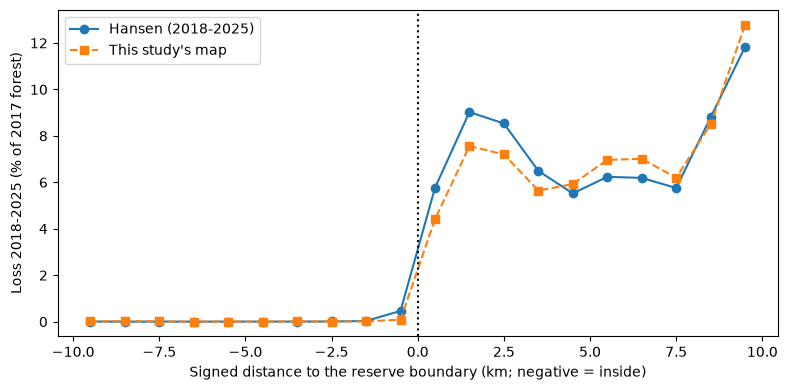

In [15]:
# [8.2] Loss rate by distance to the boundary (1 km)
rows = []
for lo in range(-10000, 10000, 1000):
    band = domain & (signed >= lo) & (signed < lo + 1000)
    fh, fm = (band & forest17_h).sum() * PIX_KM2, (band & forest17_m).sum() * PIX_KM2
    rows.append({"band_km": f"{lo / 1000:+.0f} to {(lo + 1000) / 1000:+.0f}",
                 "center_km": (lo + 500) / 1000,
                 "forest_km2": fh,
                 "hansen_loss_%": 100 * (band & loss_h).sum() * PIX_KM2 / fh if fh >= 2 else np.nan,
                 "map_loss_%": 100 * (band & loss_m).sum() * PIX_KM2 / fm if fm >= 2 else np.nan})
profile_1km = pd.DataFrame(rows)
print(profile_1km[["band_km", "forest_km2", "hansen_loss_%", "map_loss_%"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(profile_1km.center_km, profile_1km["hansen_loss_%"], "o-", label="Hansen (2018-2025)")
ax.plot(profile_1km.center_km, profile_1km["map_loss_%"], "s--", label="This study's map")
ax.axvline(0, color="k", linestyle=":")
ax.set_xlabel("Signed distance to the reserve boundary (km; negative = inside)")
ax.set_ylabel("Loss 2018-2025 (% of 2017 forest)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/boundary_profile.png", dpi=200)
plt.show()

### 8.3 Matched boundary segments at 250 m
Only inside pixels whose nearest outside pixel belongs to the ring are kept, so both sides of each segment are comparable (this drops the southern boundary, which touches an excluded indigenous land). At 250 m the change is a **ramp of about 1 km on each side** rather than a step at the line, and its midpoint lies roughly 300 m outside the official boundary. Possible reasons, not tested: positional imprecision of WDPA boundaries, forest strips kept along the boundary, edge degradation.

        band_m  forest_km2  hansen_loss_%  map_loss_%
-2000 to -1750       61.85           0.00        0.01
-1750 to -1500       64.08           0.00        0.01
-1500 to -1250       66.81           0.00        0.02
-1250 to -1000       67.50           0.00        0.01
 -1000 to -750       70.08           0.06        0.08
  -750 to -500       72.44           0.21        0.08
  -500 to -250       75.12           0.55        0.07
    -250 to +0       74.53           0.88        0.16
    +0 to +250       52.69           2.22        1.14
  +250 to +500       73.13           4.38        2.97
  +500 to +750       70.83           6.89        5.39
 +750 to +1000       69.73           8.72        7.20
+1000 to +1250       64.06           9.45        7.99
+1250 to +1500       63.10           9.31        7.77
+1500 to +1750       62.88           9.00        7.37
+1750 to +2000       60.47           8.31        7.09


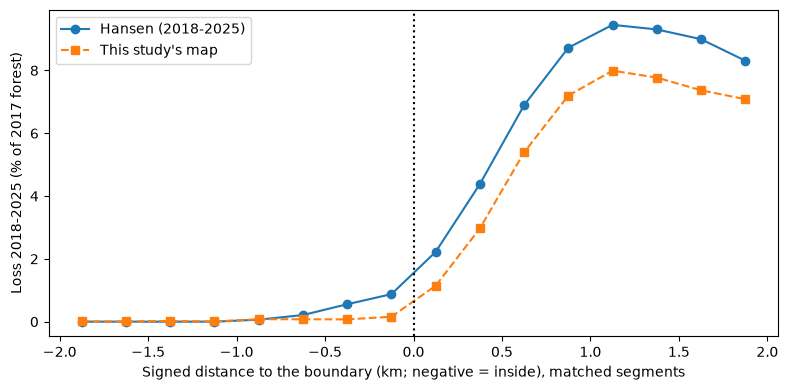

In [16]:
# [8.3] Matched boundary segments (250 m)
# Matched boundary segments: inside pixels whose nearest outside pixel belongs to the ring
d_edt, idx = ndimage.distance_transform_edt(inside, return_indices=True)
matched_in = inside & ring[idx[0], idx[1]]
del idx, d_edt

rows = []
for lo in range(-2000, 2000, 250):
    segment = matched_in if lo < 0 else ring
    band = segment & (signed >= lo) & (signed < lo + 250)
    fh, fm = (band & forest17_h).sum() * PIX_KM2, (band & forest17_m).sum() * PIX_KM2
    rows.append({"band_m": f"{lo:+d} to {lo + 250:+d}", "center_km": (lo + 125) / 1000,
                 "forest_km2": fh,
                 "hansen_loss_%": 100 * (band & loss_h).sum() * PIX_KM2 / fh if fh >= 0.5 else np.nan,
                 "map_loss_%": 100 * (band & loss_m).sum() * PIX_KM2 / fm if fm >= 0.5 else np.nan})
fine = pd.DataFrame(rows)
print(fine[["band_m", "forest_km2", "hansen_loss_%", "map_loss_%"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(fine.center_km, fine["hansen_loss_%"], "o-", label="Hansen (2018-2025)")
ax.plot(fine.center_km, fine["map_loss_%"], "s--", label="This study's map")
ax.axvline(0, color="k", linestyle=":")
ax.set_xlabel("Signed distance to the boundary (km; negative = inside), matched segments")
ax.set_ylabel("Loss 2018-2025 (% of 2017 forest)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/boundary_profile_matched.png", dpi=200)
plt.show()

### 8.4 Comparison at equal exposure
For every forest pixel, the distance to the nearest **non-forest pixel outside the reserve** in 2017 is a rough proxy for exposure to the deforestation front. Rivers and natural openings count as non-forest, so this is a coarse indicator. Loss rates are compared inside and in the ring within the same distance classes, and a **direct standardisation** gives the loss rate the reserve would have if it had the ring's rates at equal exposure.

Most of the reserve's forest (more than two thirds) is more than 5 km from the front, a class that is almost absent from the ring: the standardisation over all classes extrapolates the ring's rate for that class from only a few km² of forest. Step 8.5 therefore repeats it on the classes present in both zones.

In [17]:
# [8.4] Comparison at equal exposure
# Distance (m) to the nearest non-forest pixel OUTSIDE the reserve, in 2017
target = (~forest17_h) & (~inside)                    # external non-forest (Hansen)
dist_front = ndimage.distance_transform_edt(~target) * PIX_M

edges = [0, 500, 1000, 2000, 5000, np.inf]
dist_classes = ["0-0.5 km", "0.5-1 km", "1-2 km", "2-5 km", ">5 km"]

rows = []
for zone, zmask in (("inside", inside), ("ring", ring)):
    fz = zmask & forest17_h
    total = fz.sum()
    for k, name in enumerate(dist_classes):
        band = fz & (dist_front >= edges[k]) & (dist_front < edges[k + 1])
        rows.append({"zone": zone, "class": name,
                     "forest_km2": band.sum() * PIX_KM2,
                     "share_%": 100 * band.sum() / total,
                     "hansen_loss_%": 100 * (band & loss_h).sum() / max(band.sum(), 1)})
tbl = pd.DataFrame(rows)
print(tbl.round(2).to_string(index=False))

# Direct standardisation: the reserve's exposure mix with the ring's loss rates
rate_ring = tbl[tbl.zone == "ring"].set_index("class")["hansen_loss_%"]
rate_in = tbl[tbl.zone == "inside"].set_index("class")["hansen_loss_%"]
share_in = tbl[tbl.zone == "inside"].set_index("class")["share_%"] / 100
expected_in = (share_in * rate_ring).sum()
observed_in = 100 * (inside & loss_h).sum() / (inside & forest17_h).sum()
observed_ring = 100 * (ring & loss_h).sum() / (ring & forest17_h).sum()
print(f"\nHansen loss rate, ring (observed): {observed_ring:.2f} %")
print(f"Hansen loss rate, reserve (observed): {observed_in:.3f} %")
print(f"Reserve if it had the ring's rates at equal exposure: {expected_in:.2f} %")
print(f"Ratio expected / observed in the reserve: {expected_in / max(observed_in, 1e-6):.0f}")

  zone    class  forest_km2  share_%  hansen_loss_%
inside 0-0.5 km       67.66     1.99           0.06
inside 0.5-1 km       81.02     2.38           0.28
inside   1-2 km      189.05     5.56           0.47
inside   2-5 km      709.30    20.87           0.04
inside    >5 km     2351.55    69.19           0.02
  ring 0-0.5 km      963.69    43.76          12.59
  ring 0.5-1 km      534.42    24.26           3.88
  ring   1-2 km      437.55    19.87           3.97
  ring   2-5 km      263.86    11.98           1.20
  ring    >5 km        2.95     0.13           0.09

Hansen loss rate, ring (observed): 7.38 %
Hansen loss rate, reserve (observed): 0.052 %
Reserve if it had the ring's rates at equal exposure: 0.88 %
Ratio expected / observed in the reserve: 17


### 8.5 Standardisation on the common support (new)
The same standardisation restricted to the exposure classes present in both zones (0 to 5 km), re-weighted to the reserve's mix within those classes. It does not depend on the ring's rate for the almost empty ">5 km" class. Run it to see the result.

In [18]:
# [8.5] Standardisation on the common support (new)
common = ["0-0.5 km", "0.5-1 km", "1-2 km", "2-5 km"]
share_c = share_in.loc[common] / share_in.loc[common].sum()      # reserve's mix within the common classes
expected_c = (share_c * rate_ring.loc[common]).sum()
observed_c = (share_c * rate_in.loc[common]).sum()
print(f"Reserve forest in the common classes: "
      f"{tbl[(tbl.zone == 'inside') & tbl['class'].isin(common)].forest_km2.sum():.0f} km2 "
      f"({100 * share_in.loc[common].sum():.0f} % of its forest)")
print(f"Expected with the ring's rates: {expected_c:.2f} % | observed: {observed_c:.3f} %")
print(f"Ratio expected / observed: {expected_c / max(observed_c, 1e-6):.0f}")

Reserve forest in the common classes: 1047 km2 (31 % of its forest)
Expected with the ring's rates: 2.64 % | observed: 0.134 %
Ratio expected / observed: 20


## Step 9. Final figures
Saved in `figures/`: the loss map, annual loss curves and the accuracy matrix (the two boundary profiles were saved in step 8). Run steps 6.5 to 8.1 first; the figure outputs are not stored in this notebook.

### 9.1 Loss map
Persistent loss 2018-2025 over the 10 km ring and the reserve (solid line). Loss is shown only inside the study area (other protected areas excluded from the ring stay white). The map shows loss concentrated on the western flank, a dense early clearing in the south-west, and a few large rectangular clearings in the east and north-east.

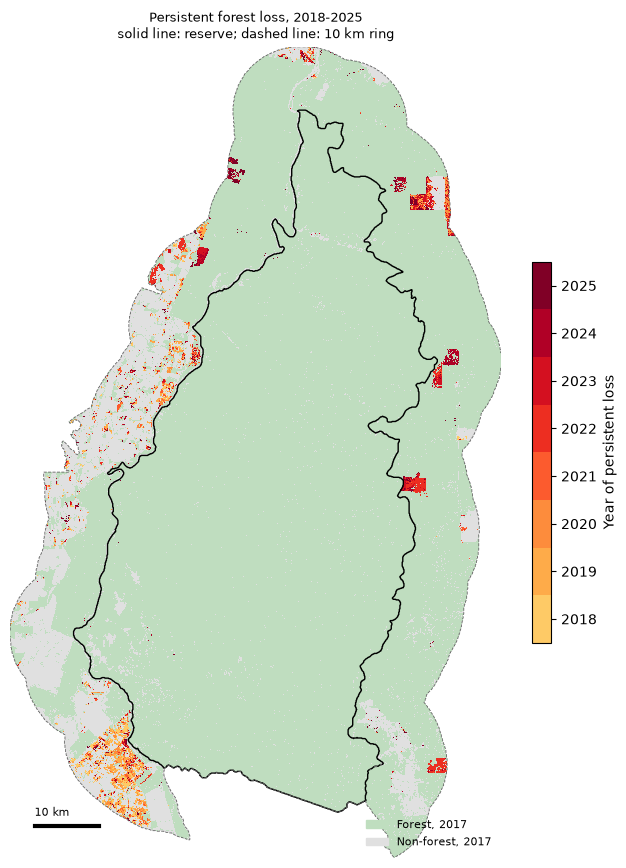

In [19]:
# [9.1] Loss map
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

STEP = 3                                                  # display at 90 m
r_ = np.where(domain.any(axis=1))[0]
c_ = np.where(domain.any(axis=0))[0]
sl = (slice(r_[0], r_[-1] + 1, STEP), slice(c_[0], c_[-1] + 1, STEP))
dom, ins, fm, ly_show = domain[sl], inside[sl], forest17_m[sl], loss_map_year[sl]
ly_show = np.where(dom, ly_show, 0)                       # show loss only inside the study area

img = np.ones(dom.shape + (3,))
img[dom & ~fm] = (0.88, 0.88, 0.88)                       # non-forest in 2017
img[dom & fm] = (0.75, 0.87, 0.75)                        # forest in 2017
cmap = ListedColormap(plt.cm.YlOrRd(np.linspace(0.3, 1.0, 8)))   # one visible colour per year

fig, ax = plt.subplots(figsize=(6.5, 9))
ax.imshow(img, interpolation="nearest")
im = ax.imshow(np.ma.masked_where(ly_show == 0, ly_show), cmap=cmap,
               vmin=2017.5, vmax=2025.5, interpolation="nearest")
ax.contour(ins.astype(float), levels=[0.5], colors="k", linewidths=1.0)
ax.contour(dom.astype(float), levels=[0.5], colors="0.4", linewidths=0.6, linestyles="--")
cb = plt.colorbar(im, ax=ax, shrink=0.45, ticks=range(2018, 2026))
cb.set_label("Year of persistent loss")
ax.legend(handles=[Patch(color=(0.75, 0.87, 0.75), label="Forest, 2017"),
                   Patch(color=(0.88, 0.88, 0.88), label="Non-forest, 2017")],
          loc="lower right", fontsize=8, frameon=False)
h, w = dom.shape
x0, y0 = w * 0.05, h * 0.96
ax.plot([x0, x0 + 10000 / (PIX_M * STEP)], [y0, y0], "k", linewidth=3)
ax.text(x0, y0 - h * 0.012, "10 km", fontsize=8)
ax.set_xlim(0, w)
ax.set_ylim(h, 0)
ax.set_title("Persistent forest loss, 2018-2025\nsolid line: reserve; dashed line: 10 km ring",
             fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/loss_map.png", dpi=200)
plt.show()

### 9.2 Annual loss, ring and reserve
Loss in each year as a share of 2017 forest, from Hansen and from this study's map. In the ring both products show a decline, but they **diverge in 2024-2025** (the cause was not established; possible reasons are the persistence rule counting a single non-forest year in 2025, the dry-season window shifting the year attributed to late-year losses, and lower completeness of the latest Hansen years). The reserve panel has a very different scale: values there amount to a few pixels.

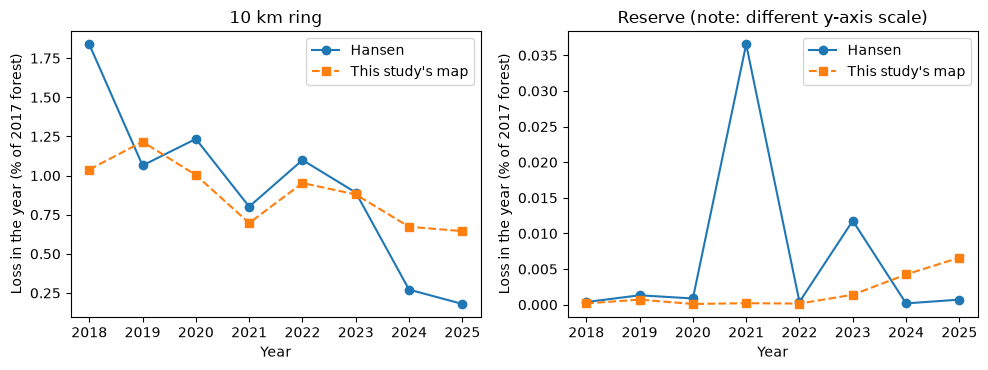

In [20]:
# [9.2] Annual loss, ring and reserve
years = list(range(2018, 2026))

def annual(zone):
    f_h, f_m = (zone & forest17_h).sum(), (zone & forest17_m).sum()
    hansen_rate = [100 * (zone & forest17_h & (lossyear == y - 2000)).sum() / f_h for y in years]
    map_rate = [100 * (zone & (loss_map_year == y)).sum() / f_m for y in years]
    return hansen_rate, map_rate

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (name, zone) in zip(axes, (("10 km ring", ring), ("Reserve", inside))):
    hansen_rate, map_rate = annual(zone)
    ax.plot(years, hansen_rate, "o-", label="Hansen")
    ax.plot(years, map_rate, "s--", label="This study's map")
    ax.set_title(f"{name} (note: different y-axis scale)" if name == "Reserve" else name)
    ax.set_xlabel("Year")
    ax.set_ylabel("Loss in the year (% of 2017 forest)")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/annual_loss.png", dpi=200)
plt.show()

### 9.3 Accuracy matrix
Left: counts of validation points by map stratum and analyst label (ring). Right: loss versus no-loss matrix in km² with user's and producer's accuracy (95 % bootstrap intervals). Requires steps 7.5 and 7.6.

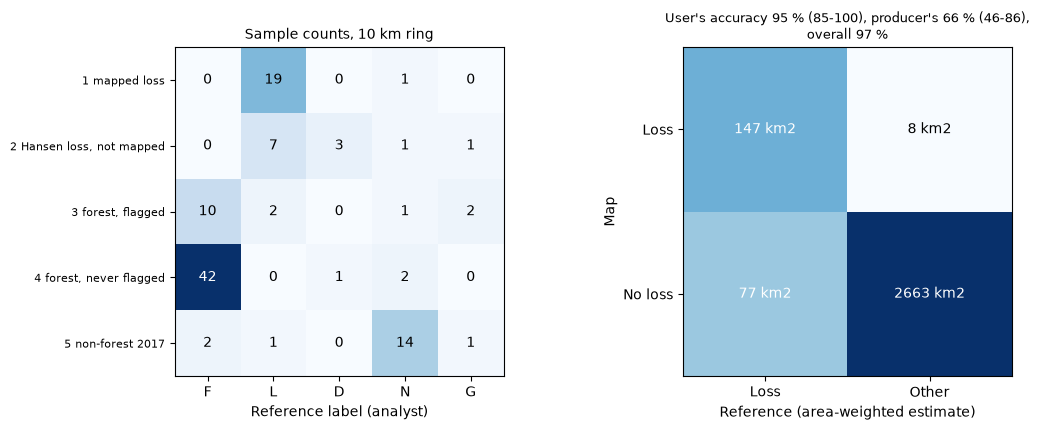

In [21]:
# [9.3] Accuracy matrix
est, ci = run("ring")
d = df_ref[df_ref.zone == "ring"]
ct = pd.crosstab(d.stratum, d.label).reindex(columns=list("FLDNG"), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))

ax = axes[0]
ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(5))
ax.set_xticklabels(ct.columns)
ax.set_yticks(range(5))
ax.set_yticklabels(["1 mapped loss", "2 Hansen loss, not mapped", "3 forest, flagged",
                    "4 forest, never flagged", "5 non-forest 2017"], fontsize=8)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        ax.text(j, i, int(ct.values[i, j]), ha="center", va="center",
                color="white" if ct.values[i, j] > ct.values.max() / 2 else "black")
ax.set_xlabel("Reference label (analyst)")
ax.set_title("Sample counts, 10 km ring", fontsize=10)

ax = axes[1]
mat = np.array([[est["tp"], est["fp"]], [est["fn"], est["tn"]]])
ax.imshow(np.log10(mat + 1), cmap="Blues")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Loss", "Other"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Loss", "No loss"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{mat[i, j]:.0f} km2", ha="center", va="center",
                color="white" if np.log10(mat[i, j] + 1) > np.log10(mat.max() + 1) / 2 else "black")
ax.set_xlabel("Reference (area-weighted estimate)")
ax.set_ylabel("Map")
ax.set_title(f"User's accuracy {100 * est['UA']:.0f} % ({100 * ci['UA'][0]:.0f}-{100 * ci['UA'][1]:.0f}), "
             f"producer's {100 * est['PA']:.0f} % ({100 * ci['PA'][0]:.0f}-{100 * ci['PA'][1]:.0f}),\n"
             f"overall {100 * est['OA']:.0f} %", fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrix.png", dpi=200)
plt.show()

## Limitations to report

- **One site, chosen on contrast.** The result applies to the Jaru reserve and its ring, not to protection in general. Selection of where reserves are created and positional imprecision of boundaries can contribute to the inside/outside difference.
- **Association, not causation.** Exposure was controlled only through a coarse distance to the front (which includes rivers and natural openings). Roads, slope, land tenure and enforcement are not controlled.
- **Training labels from Hansen** carry Hansen's errors. The validation does not: it relies on analyst labels.
- **Single analyst**, labelling quickly (about 30 minutes for 220 points) and without a repeat labelling to measure consistency. Confidence 2 was used for only 10 points.
- **Small samples** in thin strata (10 to 20 points): standard errors are approximate, and a few points weigh heavily (for example one point in the ring's non-forest stratum represents several tens of km²).
- **Reserve loss is not measurable precisely.** No loss was found in the 55 points of its large stable stratum; the conservative upper bound is wide. Hansen's independent estimate there is very small.
- **Small and transient events** (below the minimum mapping unit, or recovering within a year) are not mapped.
- **Persistence rule end effect** in 2025 and a **timing offset** between the dry-season composites and Hansen's calendar-year loss.
- **2017-2018** rest on fewer observations per pixel than later years.